# PTB-XL ECG Classification — ResNet1D Baseline

**Notebook 03 / Research Pipeline: PTB-XL Self-Supervised ECG Representation Learning**

Author: Medical AI Research Team &nbsp;|&nbsp; Platform: Kaggle (Tesla T4, 16GB) &nbsp;|&nbsp; Framework: PyTorch 2.x

---
This notebook trains and evaluates a **1D ResNet** — the first supervised baseline in this project — for
multi-label diagnostic-superclass classification (NORM / MI / STTC / CD / HYP) on PTB-XL. It reuses the
preprocessing pipeline established in Notebook 02 (loading, filtering, normalization, official fold
splitting, `Dataset`/`DataLoader`) and introduces a **model-agnostic training framework**
(`Trainer`, `Evaluator`, `MetricsCalculator`, `Logger`, `CheckpointManager`, `Visualizer`) that Notebooks
04–06 will reuse unchanged — only the `model = ...` line needs to change for InceptionTime, Mamba, and
SSL+Mamba, which keeps the eventual Notebook 07 comparison fair and reproducible.

> **Note on cross-notebook reuse.** Kaggle notebooks do not natively `import` from one another. The
> preprocessing building blocks below (signal loading, filtering, normalization, `Dataset` classes) are
> therefore reproduced **unmodified** from Notebook 02 in Section 6, rather than duplicated with drift.
> In a production setting, promote Notebook 02's utility cells to a Kaggle **Utility Script** and `import`
> it from every notebook to guarantee byte-for-byte identical preprocessing.


## Section 1 — Project Overview

### 1.1 Why ResNet is a strong baseline for ECG

Deep CNNs suffer from vanishing gradients and optimization difficulty as depth increases — beyond a
certain depth, additional layers can *increase* training error, not just overfit. He et al. (2016)
showed this is an optimization problem, not a capacity problem, and solved it with **residual learning**.
The same argument transfers directly to 1D ECG signals: diagnostically relevant morphology (P wave, QRS
complex, ST segment, T wave) spans a wide range of temporal scales, which favors a moderately deep
network with a large effective receptive field — exactly the regime where residual connections matter
most.

### 1.2 Residual learning & skip connections

Instead of learning a direct mapping `H(x)`, a residual block learns the **residual** `F(x) = H(x) - x`
and reconstructs `H(x) = F(x) + x` via an identity **skip connection**. If the optimal mapping for a
block is close to identity, the residual formulation only needs to push `F(x)` toward zero — trivially
easy for the optimizer — rather than having to learn an identity mapping from scratch through nonlinear
layers. This directly stabilizes gradient flow to early layers via the additive shortcut path.

### 1.3 Advantages over a vanilla (plain) CNN

- **Trainable at greater depth** without the plain-network degradation problem.
- **Better gradient flow** — the shortcut path acts as a gradient "highway" straight to earlier layers.
- **Implicit ensembling** — a residual network behaves like an ensemble of many shallower networks of
  varying effective depth (Veit et al., 2016), which tends to improve generalization.
- **Parameter-efficient** relative to plain CNNs of comparable representational depth.

### 1.4 Prior PTB-XL research using ResNet

Strodthoff et al. (2020, "Deep Learning for ECG Analysis: Benchmarks and Insights from PTB-XL") — the
paper that established PTB-XL's official folds and superclass task used throughout this project —
benchmarked a 1D ResNet among several architectures (CNN, LSTM, Inception-style) and found it a
competitive, strong all-around baseline for the multi-label superclass task, motivating its use here as
the reference point for every later architecture in this series.

### 1.5 Expected performance

On the official PTB-XL superclass task, well-tuned 1D-CNN/ResNet baselines typically reach **macro
AUROC in the low-to-mid 0.90s** and **NORM/MI-class AUROC often above 0.93–0.95**, with rarer/harder
classes (HYP, some CD subpatterns) trailing behind due to class imbalance — this notebook's Section 20
error analysis quantifies exactly that gap on this run.


## Section 2 — Install Required Packages

In [1]:
# Section 2 — Install Required Packages
# ---------------------------------------------------------------------------
import importlib
import subprocess
import sys


def ensure_package(pkg_import_name: str, pip_name: str = None) -> None:
    '''Install a package via pip only if it is not already importable.'''
    pip_name = pip_name or pkg_import_name
    try:
        importlib.import_module(pkg_import_name)
        print(f"[OK] {pkg_import_name} already available.")
    except ImportError:
        print(f"[INSTALL] {pip_name} not found — installing quietly...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)


for import_name, pip_name in [
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("torchmetrics", "torchmetrics"),
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("plotly", "plotly"),
    ("sklearn", "scikit-learn"),
    ("tqdm", "tqdm"),
    ("thop", "thop"),
    ("tensorboard", "tensorboard"),
    ("wfdb", "wfdb"),
    ("scipy", "scipy"),
]:
    ensure_package(import_name, pip_name)


[OK] torch already available.
[OK] torchvision already available.
[OK] torchmetrics already available.
[OK] numpy already available.
[OK] pandas already available.
[OK] matplotlib already available.
[OK] plotly already available.
[OK] sklearn already available.
[OK] tqdm already available.
[INSTALL] thop not found — installing quietly...
[OK] tensorboard already available.
[INSTALL] wfdb not found — installing quietly...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.8 MB/s eta 0:00:00
[OK] scipy already available.


## Section 3 — Import Libraries

In [2]:
# Section 3 — Import Libraries
# ---------------------------------------------------------------------------

# --- Standard library -------------------------------------------------------
import os
import ast
import copy
import json
import time
import random
import warnings
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple, Union

# --- Third-party: numerical / data ------------------------------------------
import numpy as np
import pandas as pd
import scipy.signal as sp_signal
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    roc_curve, precision_recall_curve, confusion_matrix, auc,
)

# --- Third-party: visualization ----------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import plotly.express as px
import plotly.graph_objects as go

# --- Third-party: ECG I/O -----------------------------------------------------
import wfdb

# --- Third-party: deep learning -----------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler

try:
    from torch.utils.tensorboard import SummaryWriter
    _HAS_TENSORBOARD = True
except ImportError:
    _HAS_TENSORBOARD = False

try:
    from thop import profile as thop_profile
    _HAS_THOP = True
except ImportError:
    _HAS_THOP = False

# --- Progress bars -------------------------------------------------------------
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
print(f"TensorBoard     : {'available' if _HAS_TENSORBOARD else 'NOT available'}")
print(f"thop (FLOPs)    : {'available' if _HAS_THOP else 'NOT available'}")


PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4
TensorBoard     : available
thop (FLOPs)    : available


## Section 4 — Configuration

`CONFIG` mirrors Notebook 02's signal-processing constants exactly (so preprocessing stays identical)
and adds every training hyperparameter needed by the model-agnostic training framework below.


In [3]:
# Section 4 — Configuration
# ---------------------------------------------------------------------------

class CONFIG:
    '''Central configuration for the ResNet1D baseline (and every future architecture notebook).

    Signal-processing constants (SAMPLING_RATE, SIGNAL_LENGTH, N_LEADS, SUPERCLASSES, ...)
    are kept identical to Notebook 02 so preprocessing never silently drifts between notebooks.
    '''

    # ---- Dataset path (auto-detected in Section 6) --------------------------
    DATA_DIR: str = None
    RECORDS_LOW_RES: str = "records100"
    RECORDS_HIGH_RES: str = "records500"

    # ---- Signal properties (must match Notebook 02) --------------------------
    SAMPLING_RATE: int = 100
    SIGNAL_DURATION_SEC: int = 10
    SIGNAL_LENGTH: int = SAMPLING_RATE * SIGNAL_DURATION_SEC
    N_LEADS: int = 12
    LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

    # ---- Official folds / classes (must match Notebook 02) --------------------
    TRAIN_FOLDS = list(range(1, 9))
    VAL_FOLD = 9
    TEST_FOLD = 10
    SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
    N_CLASSES = len(SUPERCLASSES)

    # ---- Filtering / normalization (must match Notebook 02) --------------------
    BANDPASS_LOW_HZ: float = 0.5
    BANDPASS_HIGH_HZ: float = 40.0
    POWERLINE_FREQ_HZ: float = 50.0
    FILTER_ORDER: int = 4
    NOTCH_QUALITY_FACTOR: float = 30.0
    NORMALIZATION_TYPE: str = "zscore"

    # ---- Reproducibility --------------------------------------------------------
    RANDOM_SEED: int = 42
    DETERMINISTIC: bool = True

    # ---- Model -------------------------------------------------------------------
    MODEL_NAME: str = "resnet1d"
    RESNET_BLOCK_CHANNELS = (64, 128, 256, 512)   # per-stage output channels
    RESNET_BLOCKS_PER_STAGE = (2, 2, 2, 2)        # ResNet18-style depth
    RESNET_KERNEL_SIZE: int = 7
    DROPOUT: float = 0.3

    # ---- Training hyperparameters --------------------------------------------------
    BATCH_SIZE: int = 64
    EPOCHS: int = 50
    LEARNING_RATE: float = 1e-3
    WEIGHT_DECAY: float = 1e-4
    OPTIMIZER: str = "adamw"
    SCHEDULER: str = "cosine"          # one of {"cosine", "plateau"}
    GRAD_CLIP_NORM: float = 1.0
    USE_AMP: bool = True
    USE_FOCAL_LOSS: bool = False
    USE_CLASS_WEIGHTS: bool = True
    EARLY_STOPPING_PATIENCE: int = 10
    LOG_EVERY_N_STEPS: int = 20

    # ---- DataLoader -----------------------------------------------------------------
    NUM_WORKERS: int = 2
    PIN_MEMORY: bool = True
    PREFETCH_FACTOR: int = 4
    PERSISTENT_WORKERS: bool = True

    # ---- Device ------------------------------------------------------------------------
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # ---- Output / checkpoint / logging directories ---------------------------------------
    OUTPUT_DIR: str = "./resnet1d_outputs"
    FIGURES_DIR: str = "./resnet1d_outputs/figures"
    TABLES_DIR: str = "./resnet1d_outputs/tables"
    CHECKPOINT_DIR: str = "./resnet1d_outputs/checkpoints"
    TENSORBOARD_DIR: str = "./resnet1d_outputs/tensorboard"

    # ---- Visualization --------------------------------------------------------------------
    FIGSIZE_WIDE = (14, 5)
    FIGSIZE_SQUARE = (7, 7)
    FIGSIZE_GRID = (16, 9)
    PALETTE = "deep"


for _dir in [CONFIG.OUTPUT_DIR, CONFIG.FIGURES_DIR, CONFIG.TABLES_DIR,
             CONFIG.CHECKPOINT_DIR, CONFIG.TENSORBOARD_DIR]:
    os.makedirs(_dir, exist_ok=True)

print("CONFIG initialized.")
print(f"Model           : {CONFIG.MODEL_NAME}")
print(f"Device          : {CONFIG.DEVICE}")
print(f"Batch size      : {CONFIG.BATCH_SIZE}  |  Epochs: {CONFIG.EPOCHS}  |  LR: {CONFIG.LEARNING_RATE}")
print(f"Mixed precision : {CONFIG.USE_AMP and torch.cuda.is_available()}")


CONFIG initialized.
Model           : resnet1d
Device          : cuda
Batch size      : 64  |  Epochs: 50  |  LR: 0.001
Mixed precision : True


## Section 5 — Reproducibility

In [4]:
# Section 5 — Reproducibility
# ---------------------------------------------------------------------------

def set_global_seed(seed: int = CONFIG.RANDOM_SEED, deterministic: bool = CONFIG.DETERMINISTIC) -> None:
    '''Seed every RNG (Python, NumPy, PyTorch CPU+CUDA) for reproducible training runs.

    Parameters
    ----------
    seed : int
        Seed value.
    deterministic : bool
        If True, force deterministic cuDNN kernels (slightly slower, but makes
        this baseline's numbers exactly reproducible run-to-run — important
        for a fair Notebook 07 comparison against later architectures).
    '''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    os.environ["PYTHONHASHSEED"] = str(seed)


set_global_seed(CONFIG.RANDOM_SEED)
print(f"Global seed set to {CONFIG.RANDOM_SEED} (deterministic={CONFIG.DETERMINISTIC}).")


Global seed set to 42 (deterministic=True).


## Section 6 — Load Processed Dataset

We reuse Notebook 02's outputs (`processed_metadata.csv`, `processed_labels.csv`) and its preprocessing
building blocks (signal loading, filtering, normalization, `Dataset` classes) rather than re-deriving
labels or re-implementing preprocessing logic. The functions/classes in **6.1** are reproduced
unmodified from Notebook 02 only because Kaggle notebooks cannot `import` one another directly (see the
note at the top of this notebook) — no preprocessing decision is re-made here.


In [5]:
# Section 6.1 — Reused Preprocessing Components (unmodified from Notebook 02)
# ---------------------------------------------------------------------------

def discover_ptbxl_root(candidate_roots=None) -> str:
    '''Search common Kaggle locations for the PTB-XL raw-signal root (contains ptbxl_database.csv).'''
    search_dirs = list(candidate_roots or []) + ["/kaggle/input", "/kaggle/working", ".", ".."]
    for base in search_dirs:
        base_path = Path(base)
        if not base_path.exists():
            continue
        if (base_path / "ptbxl_database.csv").exists():
            return str(base_path)
        for path in base_path.rglob("ptbxl_database.csv"):
            return str(path.parent)
    raise FileNotFoundError(
        "Could not locate 'ptbxl_database.csv'. Attach the PTB-XL Kaggle dataset "
        "and/or set CONFIG.DATA_DIR manually."
    )


def discover_processed_artifacts(candidate_roots=None) -> Optional[str]:
    '''Search for Notebook 02's processed_metadata.csv (defines the directory holding all processed outputs).

    Returns
    -------
    str or None
        Directory containing ``processed_metadata.csv`` / ``processed_labels.csv``, or None if not found
        (caller should fall back to rebuilding labels from raw metadata).
    '''
    search_dirs = list(candidate_roots or []) + [
        "./ptbxl_preprocessing_outputs/processed",
        "/kaggle/working/ptbxl_preprocessing_outputs/processed",
        "/kaggle/input",
    ]
    for base in search_dirs:
        base_path = Path(base)
        if not base_path.exists():
            continue
        if (base_path / "processed_metadata.csv").exists():
            return str(base_path)
        for path in base_path.rglob("processed_metadata.csv"):
            return str(path.parent)
    return None


def load_signal(ecg_id: int, df: pd.DataFrame, data_dir: str = None,
                 high_res: bool = False) -> Tuple[Optional[np.ndarray], Optional[dict]]:
    '''Load one ECG waveform via WFDB, channel-first ``(n_leads, n_samples)``. (From Notebook 02, Sec. 8.)'''
    data_dir = data_dir or CONFIG.DATA_DIR
    try:
        row = df.loc[ecg_id]
    except KeyError:
        return None, None
    filename = row["filename_hr"] if high_res else row["filename_lr"]
    record_path = os.path.join(data_dir, filename)
    try:
        signal, fields = wfdb.rdsamp(record_path)
        return np.asarray(signal, dtype=np.float32).T, fields
    except Exception:
        return None, None


def bandpass_filter(signal: np.ndarray, fs: int = CONFIG.SAMPLING_RATE,
                     low: float = CONFIG.BANDPASS_LOW_HZ, high: float = CONFIG.BANDPASS_HIGH_HZ,
                     order: int = CONFIG.FILTER_ORDER) -> np.ndarray:
    '''Zero-phase Butterworth band-pass filter. (From Notebook 02, Sec. 12.)'''
    nyq = fs / 2.0
    high = min(high, nyq - 1e-3)
    b, a = sp_signal.butter(order, [low / nyq, high / nyq], btype="bandpass")
    return sp_signal.filtfilt(b, a, signal, axis=-1)


def remove_powerline_noise(signal: np.ndarray, fs: int = CONFIG.SAMPLING_RATE,
                            freq: float = CONFIG.POWERLINE_FREQ_HZ,
                            quality_factor: float = CONFIG.NOTCH_QUALITY_FACTOR) -> np.ndarray:
    '''IIR notch filter for mains interference. (From Notebook 02, Sec. 12.)'''
    nyq = fs / 2.0
    if freq >= nyq:
        return signal
    b, a = sp_signal.iirnotch(freq / nyq, quality_factor)
    return sp_signal.filtfilt(b, a, signal, axis=-1)


def preprocess_filter_pipeline(signal: np.ndarray, fs: int = CONFIG.SAMPLING_RATE) -> np.ndarray:
    '''Standard band-pass + notch filtering pipeline. (From Notebook 02, Sec. 12.)'''
    return remove_powerline_noise(bandpass_filter(signal, fs=fs), fs=fs)


def pad_or_crop(signal: np.ndarray, target_length: int = CONFIG.SIGNAL_LENGTH,
                 mode: str = "center", rng: np.random.Generator = None) -> np.ndarray:
    '''Pad/crop a signal to a fixed length. (From Notebook 02, Sec. 13.)'''
    n_leads, n_samples = signal.shape
    rng = rng or np.random.default_rng()
    if n_samples == target_length:
        return signal
    if n_samples < target_length:
        pad_total = target_length - n_samples
        pad_left = pad_total // 2 if mode == "center" else (
            rng.integers(0, pad_total + 1) if mode == "random" else 0)
        pad_right = pad_total - pad_left
        return np.pad(signal, ((0, 0), (pad_left, pad_right)), mode="constant")
    excess = n_samples - target_length
    start = int(rng.integers(0, excess + 1)) if mode == "random" else excess // 2
    return signal[:, start:start + target_length]


class SignalNormalizer:
    '''Per-lead Z-score normalizer, fit on the training fold only. (From Notebook 02, Sec. 11.)'''

    def __init__(self, method: str = CONFIG.NORMALIZATION_TYPE):
        self.method = method
        self._mean, self._std, self._fitted = None, None, False

    def fit(self, signals: Sequence[np.ndarray]) -> "SignalNormalizer":
        stacked = np.stack(signals, axis=0)
        self._mean = stacked.mean(axis=(0, 2), keepdims=True).reshape(-1, 1)
        self._std = stacked.std(axis=(0, 2), keepdims=True).reshape(-1, 1)
        self._fitted = True
        return self

    def transform(self, signal: np.ndarray, eps: float = 1e-8) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("SignalNormalizer must be fit() before transform().")
        return (signal - self._mean) / (self._std + eps)


class ECGAugmentation:
    '''Light augmentation for supervised fine-tuning (subset of Notebook 02, Sec. 14, tuned down for
    supervised training rather than SSL pretraining).'''

    def __init__(self, seed: int = None):
        self.rng = np.random.default_rng(seed)

    def __call__(self, signal: np.ndarray) -> np.ndarray:
        out = signal.copy()
        if self.rng.random() < 0.3:
            out = pad_or_crop(pad_or_crop(out, int(out.shape[-1] * 0.9), mode="random", rng=self.rng),
                               out.shape[-1], mode="center")
        if self.rng.random() < 0.5:
            out = out * self.rng.uniform(0.8, 1.2)
        if self.rng.random() < 0.2:
            n_drop = int(self.rng.integers(1, 3))
            idx = self.rng.choice(out.shape[0], size=n_drop, replace=False)
            out[idx, :] = 0.0
        if self.rng.random() < 0.5:
            out = out + self.rng.normal(0, 1, size=out.shape) * (out.std(axis=-1, keepdims=True) * 0.05)
        return out.astype(np.float32)


class PTBXLClassificationDataset(Dataset):
    '''Supervised multi-label ECG dataset. (From Notebook 02, Sec. 17.)

    Parameters
    ----------
    ecg_ids : Sequence[int]
        Which ``ecg_id`` values this instance serves.
    df : pandas.DataFrame
        PTB-XL metadata (must contain ``filename_lr``/``filename_hr``).
    label_matrix : pandas.DataFrame
        Binary (records x superclasses) indicator matrix, indexed by ``ecg_id``.
    normalizer : SignalNormalizer
        Pre-fit (on TRAIN split) normalizer.
    split : str
        One of ``{"train", "val", "test"}``; only ``"train"`` enables augmentation/random crop.
    augmenter : ECGAugmentation, optional
        Only applied when ``split == "train"``.
    '''

    def __init__(self, ecg_ids: Sequence[int], df: pd.DataFrame, label_matrix: pd.DataFrame,
                 normalizer: SignalNormalizer, split: str = "train",
                 augmenter: Optional[ECGAugmentation] = None):
        self.ecg_ids = list(ecg_ids)
        self.df = df
        self.label_matrix = label_matrix
        self.normalizer = normalizer
        self.split = split
        self.augmenter = augmenter if (augmenter is not None and split == "train") else None

    def __len__(self) -> int:
        return len(self.ecg_ids)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor, int]:
        ecg_id = self.ecg_ids[index]
        signal, _ = load_signal(ecg_id, self.df)
        if signal is None:
            signal = np.zeros((CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH), dtype=np.float32)
        signal = preprocess_filter_pipeline(signal)
        signal = pad_or_crop(signal, CONFIG.SIGNAL_LENGTH,
                              mode="random" if self.split == "train" else "center")
        signal = self.normalizer.transform(signal).astype(np.float32)
        if self.augmenter is not None:
            signal = self.augmenter(signal)
        label = self.label_matrix.loc[ecg_id].values.astype(np.float32)
        return torch.from_numpy(signal), torch.from_numpy(label), ecg_id


def build_dataloader(dataset: Dataset, batch_size: int = CONFIG.BATCH_SIZE,
                      shuffle: bool = False, num_workers: int = CONFIG.NUM_WORKERS) -> DataLoader:
    '''Kaggle-T4-tuned DataLoader. (From Notebook 02, Sec. 18.)'''
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
        pin_memory=CONFIG.PIN_MEMORY and torch.cuda.is_available(),
        prefetch_factor=CONFIG.PREFETCH_FACTOR if num_workers > 0 else None,
        persistent_workers=CONFIG.PERSISTENT_WORKERS if num_workers > 0 else False,
        drop_last=shuffle,
    )


print("Reused Notebook 02 preprocessing components loaded.")


Reused Notebook 02 preprocessing components loaded.


In [6]:
# Section 6.2 — Load Processed Metadata / Labels (with a safety-net fallback)
# ---------------------------------------------------------------------------

CONFIG.DATA_DIR = discover_ptbxl_root()
print(f"Raw PTB-XL signal root: {CONFIG.DATA_DIR}")

processed_dir = discover_processed_artifacts()

if processed_dir is not None:
    processed_metadata = pd.read_csv(os.path.join(processed_dir, "processed_metadata.csv"), index_col="ecg_id")
    label_matrix = pd.read_csv(os.path.join(processed_dir, "processed_labels.csv"), index_col="ecg_id")
    print(f"Loaded Notebook 02 processed artifacts from: {processed_dir}")
else:
    # --- Fallback: Notebook 02's output was not found as an attached dataset in this session. ---
    # This rebuilds ONLY the label-mapping step (not a new preprocessing decision — identical logic
    # to Notebook 02, Section 7) so this notebook can still run standalone if needed.
    print("[WARN] Notebook 02 processed outputs not found. Rebuilding labels/splits from raw metadata "
          "as a fallback (identical logic to Notebook 02, Section 7). For a fully reproducible run, "
          "attach Notebook 02's output folder as a Kaggle input dataset instead.")
    db_path = os.path.join(CONFIG.DATA_DIR, "ptbxl_database.csv")
    scp_path = os.path.join(CONFIG.DATA_DIR, "scp_statements.csv")
    df_ptbxl = pd.read_csv(db_path, index_col="ecg_id")
    df_ptbxl.scp_codes = df_ptbxl.scp_codes.apply(ast.literal_eval)
    df_scp = pd.read_csv(scp_path, index_col=0)

    diagnostic_scp = df_scp[df_scp["diagnostic"] == 1]
    code_to_superclass = diagnostic_scp["diagnostic_class"].to_dict()

    def _aggregate_labels(scp_codes: dict, mapping: dict) -> List[str]:
        return sorted({mapping[c] for c in scp_codes.keys() if c in mapping})

    df_ptbxl["diagnostic_superclass"] = df_ptbxl["scp_codes"].apply(
        lambda codes: _aggregate_labels(codes, code_to_superclass))
    df_ptbxl["n_labels"] = df_ptbxl["diagnostic_superclass"].apply(len)

    label_matrix = pd.DataFrame(0, index=df_ptbxl.index, columns=CONFIG.SUPERCLASSES, dtype=np.int8)
    for ecg_id, labels in df_ptbxl["diagnostic_superclass"].items():
        for label in labels:
            label_matrix.loc[ecg_id, label] = 1

    labeled = df_ptbxl[df_ptbxl["n_labels"] > 0].copy()
    labeled["split"] = None
    labeled.loc[labeled["strat_fold"].isin(CONFIG.TRAIN_FOLDS), "split"] = "train"
    labeled.loc[labeled["strat_fold"] == CONFIG.VAL_FOLD, "split"] = "val"
    labeled.loc[labeled["strat_fold"] == CONFIG.TEST_FOLD, "split"] = "test"
    processed_metadata = labeled

print(f"\nprocessed_metadata shape: {processed_metadata.shape}")
print(f"label_matrix shape      : {label_matrix.shape}")
display(processed_metadata[["patient_id", "strat_fold", "split"]].head())


Raw PTB-XL signal root: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Loaded Notebook 02 processed artifacts from: /kaggle/input/notebooks/shamsuzzamanhisham/preprocessing-reusable-data-pipeline/ptbxl_preprocessing_outputs/processed

processed_metadata shape: (21837, 30)
label_matrix shape      : (21837, 5)


,patient_id,strat_fold,split
ecg_id,,,
1,15709.0,3,train
2,13243.0,2,train
3,20372.0,5,train
4,17014.0,3,train
5,17448.0,4,train


## Section 7 — Dataset Verification

Before any training code runs, we re-verify shapes, label integrity, official fold assignment, class
distribution, and one real batch — catching any preprocessing drift immediately rather than after a
wasted training run.


train:  17111 records
  val:   2156 records
 test:   2163 records

[PASS] Every split only contains its official strat_fold value(s).

Per-split positive rate (%) by superclass:


,train,val,test
NORM,44.46,44.39,44.57
MI,25.65,25.23,25.57
STTC,24.50,24.77,24.18
CD,22.86,23.05,23.02
HYP,12.40,12.57,12.16


Fitting normalizer on train fold:   0%|          | 0/500 [00:00<?, ?it/s]


Normalizer fit on 500 training-fold signals.

Batch signals shape: (64, 12, 1000)  |  Batch labels shape: (64, 5)
[PASS] Batch shapes and label values verified.


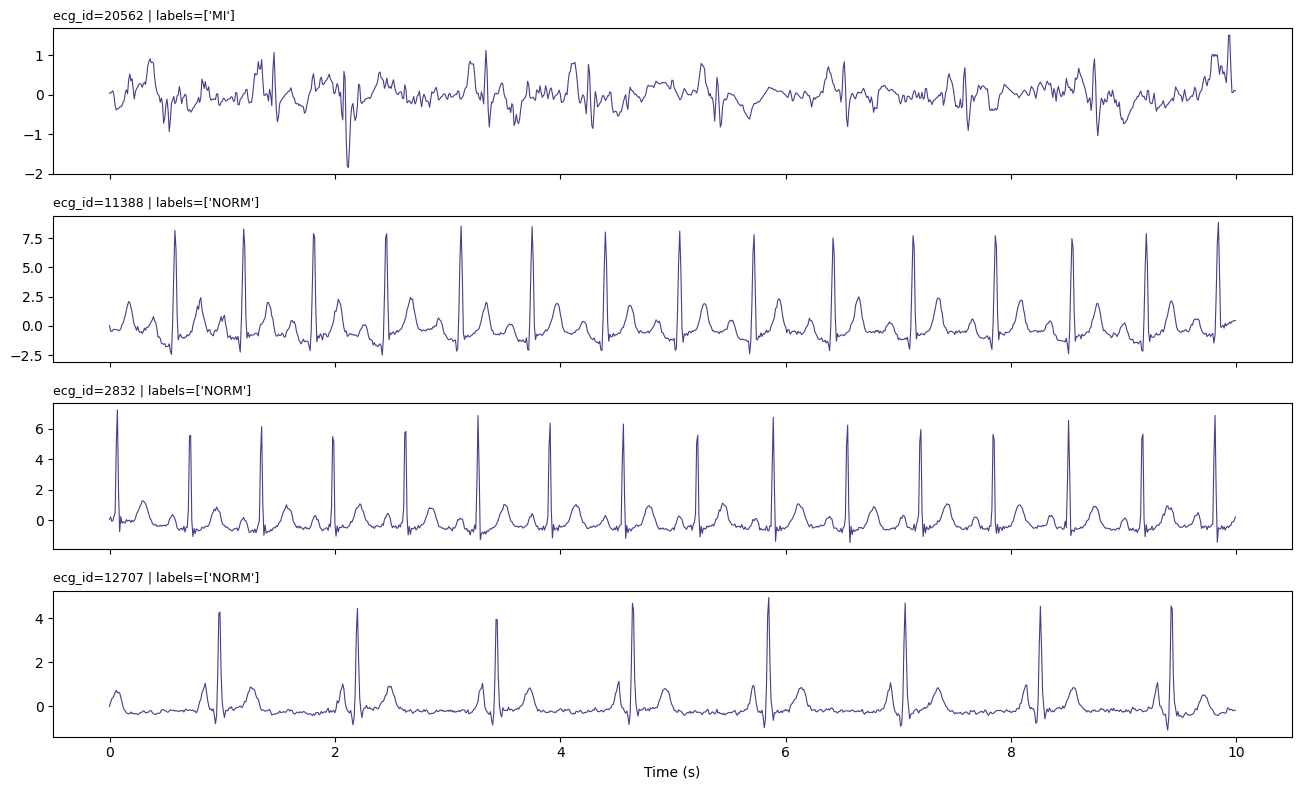

In [7]:
# Section 7 — Dataset Verification
# ---------------------------------------------------------------------------

split_ids = {
    name: processed_metadata[processed_metadata["split"] == name].index
    for name in ["train", "val", "test"]
}
for name, ids in split_ids.items():
    print(f"{name:>5}: {len(ids):>6} records")

# Fold-split correctness.
for name, expected_folds in [("train", CONFIG.TRAIN_FOLDS), ("val", [CONFIG.VAL_FOLD]), ("test", [CONFIG.TEST_FOLD])]:
    actual_folds = set(processed_metadata.loc[split_ids[name], "strat_fold"].unique())
    assert actual_folds.issubset(set(expected_folds)), f"{name} split contains unexpected folds: {actual_folds}"
print("\n[PASS] Every split only contains its official strat_fold value(s).")

# Class distribution per split.
class_dist = pd.DataFrame({
    name: label_matrix.loc[ids].mean() * 100 for name, ids in split_ids.items()
}).round(2)
print("\nPer-split positive rate (%) by superclass:")
display(class_dist)

# Fit the normalizer on the TRAIN split only (never val/test — avoids leakage).
_fit_ids = list(split_ids["train"])[:min(500, len(split_ids["train"]))]
_fit_signals = []
for _id in tqdm(_fit_ids, desc="Fitting normalizer on train fold"):
    sig, _ = load_signal(_id, processed_metadata)
    if sig is not None:
        _fit_signals.append(preprocess_filter_pipeline(sig))
normalizer = SignalNormalizer(CONFIG.NORMALIZATION_TYPE).fit(_fit_signals)
print(f"\nNormalizer fit on {len(_fit_signals)} training-fold signals.")

# Build datasets / loaders.
train_augmenter = ECGAugmentation(seed=CONFIG.RANDOM_SEED)
train_dataset = PTBXLClassificationDataset(split_ids["train"], processed_metadata, label_matrix,
                                            normalizer, split="train", augmenter=train_augmenter)
val_dataset = PTBXLClassificationDataset(split_ids["val"], processed_metadata, label_matrix,
                                          normalizer, split="val")
test_dataset = PTBXLClassificationDataset(split_ids["test"], processed_metadata, label_matrix,
                                           normalizer, split="test")

train_loader = build_dataloader(train_dataset, CONFIG.BATCH_SIZE, shuffle=True)
val_loader = build_dataloader(val_dataset, CONFIG.BATCH_SIZE, shuffle=False)
test_loader = build_dataloader(test_dataset, CONFIG.BATCH_SIZE, shuffle=False)

# Real batch shape check.
_signals, _labels, _ids = next(iter(train_loader))
print(f"\nBatch signals shape: {tuple(_signals.shape)}  |  Batch labels shape: {tuple(_labels.shape)}")
assert _signals.shape[1:] == (CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH)
assert _labels.shape[1] == CONFIG.N_CLASSES
assert set(torch.unique(_labels).tolist()).issubset({0.0, 1.0})
print("[PASS] Batch shapes and label values verified.")

# Random batch visualization.
fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
rand_idx = np.random.default_rng(CONFIG.RANDOM_SEED).choice(len(_signals), size=4, replace=False)
t = np.arange(CONFIG.SIGNAL_LENGTH) / CONFIG.SAMPLING_RATE
for ax, i in zip(axes, rand_idx):
    labels_present = [CONFIG.SUPERCLASSES[j] for j, v in enumerate(_labels[i]) if v > 0.5] or ["(none)"]
    ax.plot(t, _signals[i, 1].numpy(), linewidth=0.8, color="darkslateblue")
    ax.set_title(f"ecg_id={int(_ids[i])} | labels={labels_present}", loc="left", fontsize=9)
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG.FIGURES_DIR, "07_batch_visualization.png"))
plt.show()


## Section 8 — Model Architecture

`ResNet1D` follows the ResNet18 topology adapted to 1D signals: a wide-kernel stem convolution (kernel
7, stride 2) to capture low-frequency ECG morphology, four residual stages of doubling channel width,
global average pooling (making the network **input-length agnostic** — any `SIGNAL_LENGTH` works without
architecture changes), and a dropout + linear classification head producing 5 raw logits (sigmoid is
applied only inside the loss/inference step, never inside `forward`, per standard multi-label practice).

Each `ResidualBlock1D` uses an **identity shortcut** when input/output channels and stride match, and a
**projection shortcut** (1×1 conv + BatchNorm) otherwise — exactly as in the original ResNet paper.


In [8]:
# Section 8 — Model Architecture: ResNet1D
# ---------------------------------------------------------------------------

class ResidualBlock1D(nn.Module):
    '''A single 1D residual block: two 3-wide convolutions with a (identity or projection) shortcut.

    Parameters
    ----------
    in_channels, out_channels : int
        Input/output channel counts.
    stride : int
        Stride of the first convolution (>1 downsamples the temporal dimension).
    dropout : float
        Dropout probability applied after the second BatchNorm (before the residual add).
    '''

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, dropout: float = 0.0):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, stride=stride,
                                padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, stride=1,
                                padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU(inplace=True)

        # Projection shortcut needed whenever shape changes (channel count or stride != 1);
        # identity shortcut (no parameters) used otherwise.
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.dropout(out)
        out = out + identity          # the residual (skip) connection
        return self.relu(out)


class ResNet1D(nn.Module):
    '''ResNet18-style 1D CNN for multi-label ECG classification.

    Parameters
    ----------
    n_leads : int
        Number of input channels (12-lead ECG).
    n_classes : int
        Number of output classes (multi-label logits).
    block_channels : Sequence[int]
        Output channel width per residual stage.
    blocks_per_stage : Sequence[int]
        Number of residual blocks per stage.
    stem_kernel_size : int
        Kernel size of the initial (stem) convolution.
    dropout : float
        Dropout used inside residual blocks and before the classification head.

    Notes
    -----
    Global average pooling makes the network agnostic to the input's temporal
    length, so the exact same class handles 100 Hz or 500 Hz recordings, or any
    future re-sampling, without modification.
    '''

    def __init__(self, n_leads: int = CONFIG.N_LEADS, n_classes: int = CONFIG.N_CLASSES,
                 block_channels: Sequence[int] = CONFIG.RESNET_BLOCK_CHANNELS,
                 blocks_per_stage: Sequence[int] = CONFIG.RESNET_BLOCKS_PER_STAGE,
                 stem_kernel_size: int = CONFIG.RESNET_KERNEL_SIZE, dropout: float = CONFIG.DROPOUT):
        super().__init__()

        stem_channels = block_channels[0]
        # ---- Initial (stem) convolution: wide kernel to capture low-frequency ECG morphology ----
        self.stem = nn.Sequential(
            nn.Conv1d(n_leads, stem_channels, kernel_size=stem_kernel_size, stride=2,
                      padding=stem_kernel_size // 2, bias=False),
            nn.BatchNorm1d(stem_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )

        # ---- Residual stages ------------------------------------------------------------------
        stages = []
        in_channels = stem_channels
        for stage_idx, (out_channels, n_blocks) in enumerate(zip(block_channels, blocks_per_stage)):
            stride = 1 if stage_idx == 0 else 2   # first stage keeps stem's resolution, rest downsample
            stages.append(self._make_stage(in_channels, out_channels, n_blocks, stride, dropout))
            in_channels = out_channels
        self.stages = nn.Sequential(*stages)

        # ---- Head: Global Average Pooling -> Dropout -> Linear ---------------------------------
        self.global_avg_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(in_channels, n_classes)

        self._initialize_weights()

    @staticmethod
    def _make_stage(in_channels: int, out_channels: int, n_blocks: int, stride: int,
                     dropout: float) -> nn.Sequential:
        '''Build one residual stage: first block may downsample/change channels, rest are identity-shaped.'''
        blocks = [ResidualBlock1D(in_channels, out_channels, stride=stride, dropout=dropout)]
        for _ in range(1, n_blocks):
            blocks.append(ResidualBlock1D(out_channels, out_channels, stride=1, dropout=dropout))
        return nn.Sequential(*blocks)

    def _initialize_weights(self) -> None:
        '''He (Kaiming) initialization for convolutions — standard for ReLU networks.'''
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        '''Forward pass. ``x``: ``(batch, n_leads, n_samples)`` -> logits ``(batch, n_classes)``.

        Sigmoid is intentionally NOT applied here — use ``BCEWithLogitsLoss`` for training
        and ``torch.sigmoid(logits)`` only at inference time (Section 9/16).
        '''
        out = self.stem(x)
        out = self.stages(out)
        out = self.global_avg_pool(out).squeeze(-1)   # (batch, channels)
        out = self.dropout(out)
        return self.classifier(out)

    def get_feature_maps(self, x: torch.Tensor) -> List[torch.Tensor]:
        '''Return the output of each residual stage (for Section 18 explainability visualizations).'''
        maps = []
        out = self.stem(x)
        for stage in self.stages:
            out = stage(out)
            maps.append(out)
        return maps


def count_parameters(model: nn.Module) -> Tuple[int, int]:
    '''Return (total_params, trainable_params) for a model.'''
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def print_model_summary(model: nn.Module, input_shape: Tuple[int, int, int]) -> None:
    '''Print a lightweight, dependency-free model summary: per-stage output shapes and parameter counts.

    Parameters
    ----------
    model : nn.Module
        The model to summarize.
    input_shape : tuple[int, int, int]
        ``(batch, n_leads, n_samples)`` used for a dry forward pass.
    '''
    model.eval()
    device = next(model.parameters()).device
    with torch.no_grad():
        dummy = torch.zeros(*input_shape, device=device)
        stem_out = model.stem(dummy)
        print(f"{'Stage':<12}{'Output shape':<24}{'Params':>12}")
        print("-" * 48)
        print(f"{'stem':<12}{str(tuple(stem_out.shape)):<24}"
              f"{sum(p.numel() for p in model.stem.parameters()):>12,}")
        out = stem_out
        for i, stage in enumerate(model.stages):
            out = stage(out)
            n_params = sum(p.numel() for p in stage.parameters())
            print(f"{'stage_' + str(i + 1):<12}{str(tuple(out.shape)):<24}{n_params:>12,}")
        pooled = model.global_avg_pool(out).squeeze(-1)
        logits = model.classifier(model.dropout(pooled))
        print(f"{'head':<12}{str(tuple(logits.shape)):<24}"
              f"{sum(p.numel() for p in model.classifier.parameters()):>12,}")
    model.train()
    total, trainable = count_parameters(model)
    print("-" * 48)
    print(f"Total parameters     : {total:,}")
    print(f"Trainable parameters : {trainable:,}")


model = ResNet1D().to(CONFIG.DEVICE)
print_model_summary(model, input_shape=(2, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH))


Stage       Output shape                  Params
------------------------------------------------
stem        (2, 64, 250)                   5,504
stage_1     (2, 64, 250)                  49,664
stage_2     (2, 128, 125)                181,504
stage_3     (2, 256, 63)                 723,456
stage_4     (2, 512, 32)               2,888,704
head        (2, 5)                         2,565
------------------------------------------------
Total parameters     : 3,851,397
Trainable parameters : 3,851,397


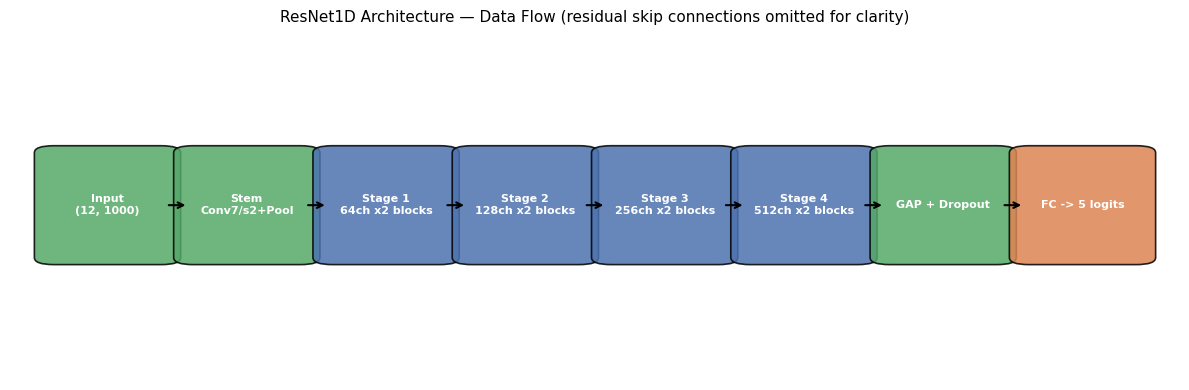

In [9]:
# Architecture diagram (publication-style block diagram of the residual stage topology).
fig, ax = plt.subplots(figsize=(12, 4))
stage_labels = ["Input\n(12, 1000)", "Stem\nConv7/s2+Pool", "Stage 1\n64ch x2 blocks",
                "Stage 2\n128ch x2 blocks", "Stage 3\n256ch x2 blocks", "Stage 4\n512ch x2 blocks",
                "GAP + Dropout", "FC -> 5 logits"]
x_positions = np.linspace(0, 1, len(stage_labels))
for x, label in zip(x_positions, stage_labels):
    color = "#4C72B0" if "Stage" in label else ("#DD8452" if "logits" in label else "#55A868")
    ax.add_patch(mpatches.FancyBboxPatch((x - 0.055, 0.35), 0.11, 0.3, boxstyle="round,pad=0.02",
                                         linewidth=1.2, edgecolor="black", facecolor=color, alpha=0.85))
    ax.text(x, 0.5, label, ha="center", va="center", fontsize=8, fontweight="bold", color="white")
for x1, x2 in zip(x_positions[:-1], x_positions[1:]):
    ax.annotate("", xy=(x2 - 0.06, 0.5), xytext=(x1 + 0.06, 0.5),
                arrowprops=dict(arrowstyle="->", lw=1.5, color="black"))
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("ResNet1D Architecture — Data Flow (residual skip connections omitted for clarity)", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG.FIGURES_DIR, "08_architecture_diagram.png"))
plt.show()


## Section 9 — Loss Function

### Why CrossEntropy is not suitable

`CrossEntropyLoss` (with softmax) assumes **mutually exclusive** classes — exactly one correct class per
sample. PTB-XL's diagnostic superclasses are **not** mutually exclusive (Section 7's positive-rate table
already shows co-occurring labels), so softmax would incorrectly force class probabilities to compete
against each other even when a record genuinely has both, e.g., MI and STTC findings.

### Multi-label classification -> `BCEWithLogitsLoss`

Each of the 5 superclasses is treated as an **independent binary classification** problem with its own
sigmoid output; `BCEWithLogitsLoss` (sigmoid + binary cross-entropy fused for numerical stability) is the
standard choice, and supports a `pos_weight` per class to counteract the class imbalance quantified in
Notebook 01/02.

We additionally implement an optional `FocalLoss` — down-weights easy (already well-classified) examples
so the model concentrates gradient signal on hard/rare-class examples, which can help minority classes
like HYP.


In [10]:
# Section 9 — Loss Function
# ---------------------------------------------------------------------------

def compute_class_weights(label_matrix: pd.DataFrame, ids: Sequence[int]) -> torch.Tensor:
    '''Compute inverse-frequency positive-class weights for BCEWithLogitsLoss's ``pos_weight``.

    Parameters
    ----------
    label_matrix : pandas.DataFrame
        Binary indicator matrix.
    ids : Sequence[int]
        Which records to compute weights from (training split only).

    Returns
    -------
    torch.Tensor
        Shape ``(n_classes,)``; weight = (n_negative / n_positive), clipped to avoid extreme values.
    '''
    sub = label_matrix.loc[ids]
    n_pos = sub.sum().values.astype(np.float32)
    n_neg = (len(sub) - n_pos).astype(np.float32)
    weights = np.clip(n_neg / np.maximum(n_pos, 1.0), 0.5, 10.0)
    return torch.tensor(weights, dtype=torch.float32)


class FocalLoss(nn.Module):
    '''Multi-label focal loss: down-weights easy examples to focus training on hard/rare cases.

    Parameters
    ----------
    alpha : float
        Balances positive vs. negative examples.
    gamma : float
        Focusing parameter; higher values down-weight easy examples more aggressively.
    pos_weight : torch.Tensor, optional
        Optional per-class positive weight, combined with the focal modulation.
    '''

    def __init__(self, alpha: float = 0.25, gamma: float = 2.0, pos_weight: torch.Tensor = None):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.pos_weight = pos_weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy_with_logits(
            logits, targets, pos_weight=self.pos_weight, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_term = (1 - p_t) ** self.gamma
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * focal_term * bce).mean()


class_weights = compute_class_weights(label_matrix, split_ids["train"]).to(CONFIG.DEVICE)
print("Per-class pos_weight (inverse frequency, clipped):")
for cls, w in zip(CONFIG.SUPERCLASSES, class_weights.tolist()):
    print(f"  {cls:>5}: {w:.2f}")

if CONFIG.USE_FOCAL_LOSS:
    criterion = FocalLoss(pos_weight=class_weights if CONFIG.USE_CLASS_WEIGHTS else None)
    print("\nUsing FocalLoss.")
else:
    criterion = nn.BCEWithLogitsLoss(pos_weight=class_weights if CONFIG.USE_CLASS_WEIGHTS else None)
    print("\nUsing BCEWithLogitsLoss" + (" with class weights." if CONFIG.USE_CLASS_WEIGHTS else "."))


Per-class pos_weight (inverse frequency, clipped):
   NORM: 1.25
     MI: 2.90
   STTC: 3.08
     CD: 3.37
    HYP: 7.07

Using BCEWithLogitsLoss with class weights.


## Section 10 — Optimizer

**AdamW** (decoupled weight decay) is used rather than vanilla Adam or SGD. Standard Adam applies weight
decay through the L2-regularized gradient, which interacts with Adam's adaptive per-parameter learning
rates in a way that weakens its regularization effect (Loshchilov & Hutter, 2019). AdamW decouples weight
decay from the gradient-based update, giving more predictable regularization — empirically the more
robust default for modern CNN/Transformer-style training, and the same choice we'll keep across
Notebooks 04–06 for a fair comparison.


In [11]:
# Section 10 — Optimizer
# ---------------------------------------------------------------------------

def build_optimizer(model: nn.Module, name: str = CONFIG.OPTIMIZER, lr: float = CONFIG.LEARNING_RATE,
                     weight_decay: float = CONFIG.WEIGHT_DECAY) -> torch.optim.Optimizer:
    '''Build the training optimizer.

    Parameters
    ----------
    model : nn.Module
        Model whose parameters will be optimized.
    name : str
        Currently supports ``"adamw"`` (default) and ``"adam"``/``"sgd"`` for ablation.
    lr : float
        Base learning rate.
    weight_decay : float
        Decoupled (AdamW) or L2 (SGD/Adam) weight decay coefficient.
    '''
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer: {name}")


optimizer = build_optimizer(model)
print(f"Optimizer: {optimizer.__class__.__name__}  |  lr={CONFIG.LEARNING_RATE}  |  "
      f"weight_decay={CONFIG.WEIGHT_DECAY}")


Optimizer: AdamW  |  lr=0.001  |  weight_decay=0.0001


## Section 11 — Learning Rate Scheduler

**`CosineAnnealingLR`** (default) smoothly decays the learning rate over `CONFIG.EPOCHS` following a
cosine curve — no hyperparameter tuning required (unlike step schedules) and empirically produces
smoother convergence and often better final minima than plateau-based decay.

**`ReduceLROnPlateau`** (alternative, offered for ablation) instead reduces the LR only when validation
AUROC stalls. It reacts to the *actual* validation signal rather than a fixed epoch schedule, which can
help when the optimal training-length is not known in advance, but requires tuning `patience`/`factor`
and can be slower to react on noisy small-validation-set metrics (PTB-XL's fold 9 is a modest ~2100
records).


In [12]:
# Section 11 — Learning Rate Scheduler
# ---------------------------------------------------------------------------

def build_scheduler(optimizer: torch.optim.Optimizer, name: str = CONFIG.SCHEDULER,
                     epochs: int = CONFIG.EPOCHS):
    '''Build the LR scheduler.

    Parameters
    ----------
    optimizer : torch.optim.Optimizer
    name : str
        One of ``{"cosine", "plateau"}``.
    epochs : int
        Total planned epochs (used by the cosine schedule's period).
    '''
    if name == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    if name == "plateau":
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    raise ValueError(f"Unknown scheduler: {name}")


scheduler = build_scheduler(optimizer)
print(f"Scheduler: {scheduler.__class__.__name__}")


Scheduler: CosineAnnealingLR


## Section 12 — Metrics

`MetricsCalculator` computes the full multi-label evaluation suite from raw probabilities/labels:
subset (exact-match) accuracy, macro/micro precision/recall/F1, macro/micro/per-class AUROC. Macro
metrics average per-class scores equally (sensitive to rare-class performance); micro metrics pool all
predictions before scoring (dominated by frequent classes) — reporting **both** is standard practice for
imbalanced multi-label clinical tasks and is exactly what lets Notebook 07 compare architectures fairly
on both "overall" and "per-class-fair" terms.


In [13]:
# Section 12 — Metrics
# ---------------------------------------------------------------------------

class MetricsCalculator:
    '''Computes the full multi-label evaluation metric suite used throughout this project.

    Parameters
    ----------
    class_names : Sequence[str]
        Ordered superclass names, matching label-matrix column order.
    threshold : float
        Probability threshold for converting sigmoid outputs to binary predictions
        (used by accuracy/precision/recall/F1; AUROC is threshold-free).
    '''

    def __init__(self, class_names: Sequence[str] = CONFIG.SUPERCLASSES, threshold: float = 0.5):
        self.class_names = list(class_names)
        self.threshold = threshold

    def compute(self, y_true: np.ndarray, y_prob: np.ndarray) -> Dict[str, Union[float, dict]]:
        '''Compute every metric for one (labels, probabilities) pair.

        Parameters
        ----------
        y_true : numpy.ndarray
            Shape ``(n_samples, n_classes)``, binary ground truth.
        y_prob : numpy.ndarray
            Shape ``(n_samples, n_classes)``, predicted probabilities in ``[0, 1]``.

        Returns
        -------
        dict
            Flat dict of scalar metrics plus a ``"per_class_auroc"`` dict.
        '''
        y_pred = (y_prob >= self.threshold).astype(int)

        subset_acc = accuracy_score(y_true, y_pred)   # exact match across all classes

        precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
            y_true, y_pred, average="macro", zero_division=0)
        precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(
            y_true, y_pred, average="micro", zero_division=0)

        per_class_auroc = {}
        for i, cls in enumerate(self.class_names):
            if len(np.unique(y_true[:, i])) < 2:
                per_class_auroc[cls] = float("nan")   # AUROC undefined with a single class present
            else:
                per_class_auroc[cls] = roc_auc_score(y_true[:, i], y_prob[:, i])

        valid_aurocs = [v for v in per_class_auroc.values() if not np.isnan(v)]
        macro_auroc = float(np.mean(valid_aurocs)) if valid_aurocs else float("nan")
        try:
            micro_auroc = roc_auc_score(y_true, y_prob, average="micro")
        except ValueError:
            micro_auroc = float("nan")

        return {
            "subset_accuracy": subset_acc,
            "precision_macro": precision_macro, "recall_macro": recall_macro, "f1_macro": f1_macro,
            "precision_micro": precision_micro, "recall_micro": recall_micro, "f1_micro": f1_micro,
            "auroc_macro": macro_auroc, "auroc_micro": micro_auroc,
            "per_class_auroc": per_class_auroc,
        }


metrics_calculator = MetricsCalculator()
print("MetricsCalculator ready:", [
    "subset_accuracy", "precision_macro/micro", "recall_macro/micro",
    "f1_macro/micro", "auroc_macro/micro", "per_class_auroc",
])


MetricsCalculator ready: ['subset_accuracy', 'precision_macro/micro', 'recall_macro/micro', 'f1_macro/micro', 'auroc_macro/micro', 'per_class_auroc']


## Section 13 — Mixed Precision Training

`torch.amp.autocast` runs eligible ops (mostly matmul/conv) in FP16 while keeping numerically sensitive
ops (e.g. batch-norm reductions, softmax) in FP32 automatically. Combined with `GradScaler` — which
scales the loss up before `backward()` to prevent FP16 gradient underflow, then unscales before the
optimizer step — this roughly **halves activation memory** and can give a **1.5-3x** throughput
speedup on the T4's Tensor Cores, letting us use a larger batch size within the 16GB budget without
sacrificing convergence stability.


In [14]:
# Section 13 — Mixed Precision Training
# ---------------------------------------------------------------------------

use_amp = CONFIG.USE_AMP and torch.cuda.is_available()
amp_device_type = "cuda" if torch.cuda.is_available() else "cpu"
grad_scaler = GradScaler(enabled=use_amp)

print(f"Mixed precision (AMP) enabled: {use_amp}")
if use_amp:
    print("Expect ~30-60% lower activation memory and faster matmul/conv throughput on the T4's Tensor Cores.")
else:
    print("Running in full FP32 (no CUDA device detected in this session, or AMP disabled in CONFIG).")


Mixed precision (AMP) enabled: True
Expect ~30-60% lower activation memory and faster matmul/conv throughput on the T4's Tensor Cores.


## Section 14 — Training Pipeline

This section defines the **model-agnostic training framework** — `Logger`, `CheckpointManager`, and
`Trainer` — that Notebooks 04-06 will reuse verbatim. None of these classes reference `ResNet1D` by
name; they operate on any `nn.Module` that outputs `(batch, n_classes)` logits, so swapping in
`InceptionTime`, `Mamba`, or `SSLMamba` later requires changing only the `model = ...` line in Section 8.


In [15]:
# Section 14.1 — Logger
# ---------------------------------------------------------------------------

class Logger:
    '''Lightweight training logger: console printing, in-memory history, and optional TensorBoard.

    Parameters
    ----------
    log_dir : str
        TensorBoard log directory (only used if TensorBoard is available).
    use_tensorboard : bool
        Whether to also mirror scalars to TensorBoard.
    '''

    def __init__(self, log_dir: str = CONFIG.TENSORBOARD_DIR, use_tensorboard: bool = True):
        self.history: Dict[str, List[float]] = {}
        self.writer = None
        if use_tensorboard and _HAS_TENSORBOARD:
            self.writer = SummaryWriter(log_dir=log_dir)

    def log_scalar(self, tag: str, value: float, step: int) -> None:
        '''Record one scalar value under ``tag`` for both in-memory history and TensorBoard.'''
        self.history.setdefault(tag, []).append(value)
        if self.writer is not None:
            self.writer.add_scalar(tag, value, step)

    def log_epoch(self, epoch: int, train_metrics: dict, val_metrics: dict, lr: float) -> None:
        '''Log a full epoch's train/val metrics plus the current learning rate.'''
        for k, v in train_metrics.items():
            if isinstance(v, (int, float)):
                self.log_scalar(f"train/{k}", v, epoch)
        for k, v in val_metrics.items():
            if isinstance(v, (int, float)):
                self.log_scalar(f"val/{k}", v, epoch)
        self.log_scalar("lr", lr, epoch)

    def to_dataframe(self) -> pd.DataFrame:
        '''Export the full scalar history as a tidy DataFrame (one row per epoch where available).'''
        max_len = max((len(v) for v in self.history.values()), default=0)
        return pd.DataFrame({k: v + [np.nan] * (max_len - len(v)) for k, v in self.history.items()})

    def close(self) -> None:
        if self.writer is not None:
            self.writer.close()


class CheckpointManager:
    '''Handles saving/loading/resuming model checkpoints and tracking the best model so far.

    Parameters
    ----------
    checkpoint_dir : str
        Directory to write checkpoint files.
    model_name : str
        Used to name checkpoint files (e.g. ``best_resnet1d.pth``).
    monitor : str
        Metric key to track for "best" model selection (higher is better).
    '''

    def __init__(self, checkpoint_dir: str = CONFIG.CHECKPOINT_DIR, model_name: str = CONFIG.MODEL_NAME,
                 monitor: str = "auroc_macro"):
        self.checkpoint_dir = checkpoint_dir
        self.model_name = model_name
        self.monitor = monitor
        self.best_score = -np.inf
        os.makedirs(checkpoint_dir, exist_ok=True)

    def save_last(self, state: dict) -> str:
        '''Always overwrite the "last" checkpoint (for resuming an interrupted run).'''
        path = os.path.join(self.checkpoint_dir, f"last_checkpoint.pth")
        torch.save(state, path)
        return path

    def save_if_best(self, state: dict, score: float) -> bool:
        '''Save a new "best" checkpoint if ``score`` improves on the tracked metric.

        Returns
        -------
        bool
            True if this call produced a new best checkpoint.
        '''
        if score > self.best_score:
            self.best_score = score
            path = os.path.join(self.checkpoint_dir, f"best_{self.model_name}.pth")
            torch.save(state, path)
            return True
        return False

    def load(self, path: str, model: nn.Module, optimizer: torch.optim.Optimizer = None,
             scheduler=None, map_location=None) -> dict:
        '''Load a checkpoint into ``model`` (and optionally ``optimizer``/``scheduler`` for resuming).

        Returns
        -------
        dict
            The full checkpoint dict (including ``epoch``, ``best_score``, etc.) for the caller
            to inspect.
        '''
        checkpoint = torch.load(path, map_location=map_location or CONFIG.DEVICE, weights_only=False)
        model.load_state_dict(checkpoint["model_state_dict"])
        if optimizer is not None and "optimizer_state_dict" in checkpoint:
            optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        if scheduler is not None and checkpoint.get("scheduler_state_dict") is not None:
            scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        return checkpoint


print("Logger and CheckpointManager defined.")


Logger and CheckpointManager defined.


In [16]:
# Section 14.2 — Trainer
# ---------------------------------------------------------------------------

class Trainer:
    '''Model-agnostic training loop with AMP, gradient clipping, checkpointing, and TensorBoard logging.

    Reused unmodified across every architecture notebook in this project — only the ``model``
    instance passed in changes (ResNet1D here; InceptionTime/Mamba/SSLMamba in Notebooks 04-06).

    Parameters
    ----------
    model : nn.Module
        Any classifier producing ``(batch, n_classes)`` logits.
    optimizer, scheduler : torch.optim objects
        Standard PyTorch optimizer/scheduler.
    criterion : nn.Module
        Loss function (e.g. ``BCEWithLogitsLoss`` or ``FocalLoss``).
    device : torch.device
    grad_clip_norm : float
        Max gradient norm for ``clip_grad_norm_``; set to 0/None to disable.
    use_amp : bool
        Whether to use mixed-precision training.
    logger : Logger
    checkpoint_manager : CheckpointManager
    '''

    def __init__(self, model: nn.Module, optimizer: torch.optim.Optimizer, scheduler,
                 criterion: nn.Module, device: torch.device = CONFIG.DEVICE,
                 grad_clip_norm: float = CONFIG.GRAD_CLIP_NORM, use_amp: bool = use_amp,
                 logger: Logger = None, checkpoint_manager: CheckpointManager = None):
        self.model = model
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.criterion = criterion
        self.device = device
        self.grad_clip_norm = grad_clip_norm
        self.use_amp = use_amp
        self.scaler = GradScaler(enabled=use_amp)
        self.logger = logger or Logger()
        self.checkpoint_manager = checkpoint_manager or CheckpointManager()
        self.metrics_calculator = MetricsCalculator()

    def train_one_epoch(self, loader: DataLoader, epoch: int) -> Dict[str, float]:
        '''Run one full training epoch. Returns a dict of averaged training metrics.'''
        self.model.train()
        running_loss = 0.0
        all_labels, all_probs = [], []

        progress = tqdm(loader, desc=f"Epoch {epoch} [train]", leave=False)
        for step, (signals, labels, _) in enumerate(progress):
            signals = signals.to(self.device, non_blocking=True)
            labels = labels.to(self.device, non_blocking=True)

            self.optimizer.zero_grad(set_to_none=True)
            with autocast(device_type=amp_device_type, enabled=self.use_amp):
                logits = self.model(signals)
                loss = self.criterion(logits, labels)

            self.scaler.scale(loss).backward()
            if self.grad_clip_norm:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip_norm)
            self.scaler.step(self.optimizer)
            self.scaler.update()

            running_loss += loss.item() * signals.size(0)
            all_labels.append(labels.detach().cpu().numpy())
            all_probs.append(torch.sigmoid(logits).detach().cpu().numpy())

            if step % CONFIG.LOG_EVERY_N_STEPS == 0:
                progress.set_postfix(loss=f"{loss.item():.4f}")

        y_true = np.concatenate(all_labels)
        y_prob = np.concatenate(all_probs)
        metrics = self.metrics_calculator.compute(y_true, y_prob)
        metrics["loss"] = running_loss / len(loader.dataset)
        return metrics

    @torch.no_grad()
    def validate_one_epoch(self, loader: DataLoader, epoch: int) -> Dict[str, float]:
        '''Run one full validation epoch (no gradient computation). Returns averaged metrics.'''
        self.model.eval()
        running_loss = 0.0
        all_labels, all_probs = [], []

        progress = tqdm(loader, desc=f"Epoch {epoch} [val]", leave=False)
        for signals, labels, _ in progress:
            signals = signals.to(self.device, non_blocking=True)
            labels = labels.to(self.device, non_blocking=True)
            with autocast(device_type=amp_device_type, enabled=self.use_amp):
                logits = self.model(signals)
                loss = self.criterion(logits, labels)
            running_loss += loss.item() * signals.size(0)
            all_labels.append(labels.cpu().numpy())
            all_probs.append(torch.sigmoid(logits).cpu().numpy())

        y_true = np.concatenate(all_labels)
        y_prob = np.concatenate(all_probs)
        metrics = self.metrics_calculator.compute(y_true, y_prob)
        metrics["loss"] = running_loss / len(loader.dataset)
        return metrics

    def fit(self, train_loader: DataLoader, val_loader: DataLoader, epochs: int = CONFIG.EPOCHS,
            early_stopping_patience: int = CONFIG.EARLY_STOPPING_PATIENCE) -> pd.DataFrame:
        '''Full training loop with automatic best-model checkpointing and early stopping.

        Parameters
        ----------
        train_loader, val_loader : DataLoader
        epochs : int
            Maximum number of epochs.
        early_stopping_patience : int
            Stop training if validation ``auroc_macro`` does not improve for this many epochs.

        Returns
        -------
        pandas.DataFrame
            Per-epoch training history (also available via ``self.logger.to_dataframe()``).
        '''
        epochs_since_improvement = 0
        epoch_times = []

        for epoch in range(1, epochs + 1):
            start = time.perf_counter()
            train_metrics = self.train_one_epoch(train_loader, epoch)
            val_metrics = self.validate_one_epoch(val_loader, epoch)
            epoch_time = time.perf_counter() - start
            epoch_times.append(epoch_time)

            current_lr = self.optimizer.param_groups[0]["lr"]
            if isinstance(self.scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                self.scheduler.step(val_metrics["auroc_macro"])
            else:
                self.scheduler.step()

            self.logger.log_epoch(epoch, train_metrics, val_metrics, current_lr)
            self.logger.log_scalar("epoch_time_sec", epoch_time, epoch)

            print(f"Epoch {epoch:>3}/{epochs} | "
                  f"train_loss={train_metrics['loss']:.4f} val_loss={val_metrics['loss']:.4f} | "
                  f"val_AUROC(macro)={val_metrics['auroc_macro']:.4f} "
                  f"val_F1(macro)={val_metrics['f1_macro']:.4f} | "
                  f"lr={current_lr:.2e} | {epoch_time:.1f}s")

            state = {
                "epoch": epoch, "model_state_dict": self.model.state_dict(),
                "optimizer_state_dict": self.optimizer.state_dict(),
                "scheduler_state_dict": self.scheduler.state_dict(),
                "val_metrics": val_metrics, "config_model_name": CONFIG.MODEL_NAME,
            }
            self.checkpoint_manager.save_last(state)
            is_best = self.checkpoint_manager.save_if_best(state, val_metrics["auroc_macro"])

            if is_best:
                epochs_since_improvement = 0
            else:
                epochs_since_improvement += 1
                if epochs_since_improvement >= early_stopping_patience:
                    print(f"\n[EARLY STOPPING] No val_AUROC(macro) improvement for "
                          f"{early_stopping_patience} epochs. Stopping at epoch {epoch}.")
                    break

        self.logger.log_scalar("avg_epoch_time_sec", float(np.mean(epoch_times)), 0)
        return self.logger.to_dataframe()


logger = Logger()
checkpoint_manager = CheckpointManager(monitor="auroc_macro")
trainer = Trainer(model, optimizer, scheduler, criterion, logger=logger, checkpoint_manager=checkpoint_manager)
print("Trainer initialized. Ready to call trainer.fit(train_loader, val_loader).")


Trainer initialized. Ready to call trainer.fit(train_loader, val_loader).


## Section 15 — Validation Pipeline

Validation runs once per epoch inside `Trainer.fit` (`validate_one_epoch`, Section 14), on **fold 9
only**, with augmentation disabled and center-cropping for deterministic evaluation. The
`CheckpointManager` tracks **validation macro AUROC** as the model-selection criterion — macro rather
than micro or loss, so an architecture cannot appear to "win" purely by nailing the majority NORM class
while neglecting rare classes like HYP, which is exactly the failure mode a fair Notebook 07 comparison
must avoid.

We now actually run training.


In [17]:
# Section 15 — Run Training + Validation
# ---------------------------------------------------------------------------

training_history = trainer.fit(train_loader, val_loader, epochs=CONFIG.EPOCHS)
display(training_history.tail())


Epoch 1 [train]:   0%|          | 0/267 [00:00<?, ?it/s]

Epoch 1 [val]:   0%|          | 0/34 [00:00<?, ?it/s]

Epoch   1/50 | train_loss=0.6847 val_loss=0.7301 | val_AUROC(macro)=0.8972 val_F1(macro)=0.6653 | lr=1.00e-03 | 133.2s


Epoch 2 [train]:   0%|          | 0/267 [00:00<?, ?it/s]

Epoch 2 [val]:   0%|          | 0/34 [00:00<?, ?it/s]

...

Epoch  29/50 | train_loss=0.3613 val_loss=0.6285 | val_AUROC(macro)=0.9264 val_F1(macro)=0.7440 | lr=4.06e-04 | 68.5s


Epoch 30 [train]:   0%|          | 0/267 [00:00<?, ?it/s]

Epoch 30 [val]:   0%|          | 0/34 [00:00<?, ?it/s]

Epoch  30/50 | train_loss=0.3547 val_loss=0.6474 | val_AUROC(macro)=0.9273 val_F1(macro)=0.7399 | lr=3.76e-04 | 65.9s

[EARLY STOPPING] No val_AUROC(macro) improvement for 10 epochs. Stopping at epoch 30.


,train/subset_accuracy,train/precision_macro,train/recall_macro,train/f1_macro,train/precision_micro,train/recall_micro,train/f1_micro,train/auroc_macro,train/auroc_micro,train/loss,val/subset_accuracy,val/precision_macro,val/recall_macro,val/f1_macro,val/precision_micro,val/recall_micro,val/f1_micro,val/auroc_macro,val/auroc_micro,val/loss,lr,epoch_time_sec,avg_epoch_time_sec
25,0.602587,0.703335,0.900076,0.783008,0.729896,0.902668,0.807140,0.959824,0.961556,0.379101,0.537106,0.651008,0.838222,0.730138,0.678400,0.859436,0.758263,0.926734,0.935887,0.593165,0.000500,68.520046,NaN
26,0.606273,0.705950,0.902334,0.785863,0.732426,0.904659,0.809483,0.961149,0.962649,0.372020,0.543599,0.664857,0.844376,0.738884,0.691354,0.855869,0.764865,0.929914,0.937243,0.575953,0.000469,67.822997,NaN
27,0.607736,0.705222,0.901386,0.785108,0.731537,0.903880,0.808627,0.961108,0.962545,0.372411,0.551484,0.663580,0.825922,0.732965,0.690552,0.852658,0.763091,0.924934,0.934942,0.656476,0.000437,69.067192,NaN
28,0.615461,0.711164,0.905873,0.790476,0.737917,0.908083,0.814204,0.963359,0.964634,0.361312,0.558905,0.678564,0.828713,0.743963,0.704841,0.851944,0.771442,0.926372,0.935911,0.628454,0.000406,68.454616,NaN
29,0.619909,0.714980,0.907764,0.794085,0.741381,0.908845,0.816616,0.964604,0.965744,0.354681,0.555195,0.674612,0.822677,0.739860,0.702335,0.847663,0.768186,0.927285,0.936691,0.647369,0.000376,65.947132,NaN


## Section 16 — Testing Pipeline

`Evaluator` loads the **best** checkpoint (by validation macro AUROC, never the last epoch — avoids
picking an overfit late-training snapshot) and runs a single held-out pass over **fold 10** to produce
final test metrics and per-record predictions.


In [18]:
# Section 16 — Testing Pipeline
# ---------------------------------------------------------------------------

class Evaluator:
    '''Loads a trained checkpoint and runs inference/evaluation on a held-out DataLoader.

    Reused unmodified across every architecture notebook — swap only which ``model``
    instance is constructed before loading its state dict.

    Parameters
    ----------
    model : nn.Module
    device : torch.device
    metrics_calculator : MetricsCalculator
    '''

    def __init__(self, model: nn.Module, device: torch.device = CONFIG.DEVICE,
                 metrics_calculator: MetricsCalculator = None):
        self.model = model
        self.device = device
        self.metrics_calculator = metrics_calculator or MetricsCalculator()

    def load_checkpoint(self, path: str) -> dict:
        '''Load model weights from a checkpoint file (see CheckpointManager.load for the full version).'''
        checkpoint = torch.load(path, map_location=self.device, weights_only=False)
        self.model.load_state_dict(checkpoint["model_state_dict"])
        return checkpoint

    @torch.no_grad()
    def predict(self, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray, np.ndarray, List[int]]:
        '''Run inference over a DataLoader.

        Returns
        -------
        tuple
            ``(y_true, y_prob, y_pred, ecg_ids)``.
        '''
        self.model.eval()
        all_labels, all_probs, all_ids = [], [], []
        for signals, labels, ids in tqdm(loader, desc="Evaluating"):
            signals = signals.to(self.device, non_blocking=True)
            with autocast(device_type=amp_device_type, enabled=use_amp):
                logits = self.model(signals)
            all_labels.append(labels.numpy())
            all_probs.append(torch.sigmoid(logits).cpu().numpy())
            all_ids.extend(ids.tolist() if torch.is_tensor(ids) else list(ids))

        y_true = np.concatenate(all_labels)
        y_prob = np.concatenate(all_probs)
        y_pred = (y_prob >= self.metrics_calculator.threshold).astype(int)
        return y_true, y_prob, y_pred, all_ids

    def evaluate(self, loader: DataLoader) -> Tuple[dict, np.ndarray, np.ndarray, np.ndarray, List[int]]:
        '''Predict + compute the full metric suite in one call.'''
        y_true, y_prob, y_pred, ids = self.predict(loader)
        metrics = self.metrics_calculator.compute(y_true, y_prob)
        return metrics, y_true, y_prob, y_pred, ids


best_ckpt_path = os.path.join(CONFIG.CHECKPOINT_DIR, f"best_{CONFIG.MODEL_NAME}.pth")
evaluator = Evaluator(model)
best_checkpoint = evaluator.load_checkpoint(best_ckpt_path)
print(f"Loaded best checkpoint from epoch {best_checkpoint['epoch']} "
      f"(val_AUROC(macro)={best_checkpoint['val_metrics']['auroc_macro']:.4f})")

test_metrics, y_true_test, y_prob_test, y_pred_test, test_ecg_ids = evaluator.evaluate(test_loader)

print("\n=== Test Set Performance (fold 10) ===")
for k, v in test_metrics.items():
    if k != "per_class_auroc":
        print(f"{k:>18}: {v:.4f}")
print("\nPer-class AUROC:")
for cls, v in test_metrics["per_class_auroc"].items():
    print(f"  {cls:>5}: {v:.4f}")

predictions_df = pd.DataFrame(y_prob_test, columns=[f"prob_{c}" for c in CONFIG.SUPERCLASSES])
predictions_df.insert(0, "ecg_id", test_ecg_ids)
for i, c in enumerate(CONFIG.SUPERCLASSES):
    predictions_df[f"true_{c}"] = y_true_test[:, i]
    predictions_df[f"pred_{c}"] = y_pred_test[:, i]


Loaded best checkpoint from epoch 20 (val_AUROC(macro)=0.9314)


Evaluating:   0%|          | 0/34 [00:00<?, ?it/s]


=== Test Set Performance (fold 10) ===
   subset_accuracy: 0.5548
   precision_macro: 0.6728
      recall_macro: 0.8260
          f1_macro: 0.7388
   precision_micro: 0.7007
      recall_micro: 0.8508
          f1_micro: 0.7685
       auroc_macro: 0.9269
       auroc_micro: 0.9367

Per-class AUROC:
   NORM: 0.9453
     MI: 0.9237
   STTC: 0.9366
     CD: 0.9220
    HYP: 0.9068


## Section 17 — Visualization

`Visualizer` bundles every publication-style figure this project needs: loss/AUROC/F1/LR curves from
training history, ROC and Precision-Recall curves per class, a multi-label confusion-matrix grid, and
correct/incorrect prediction examples.


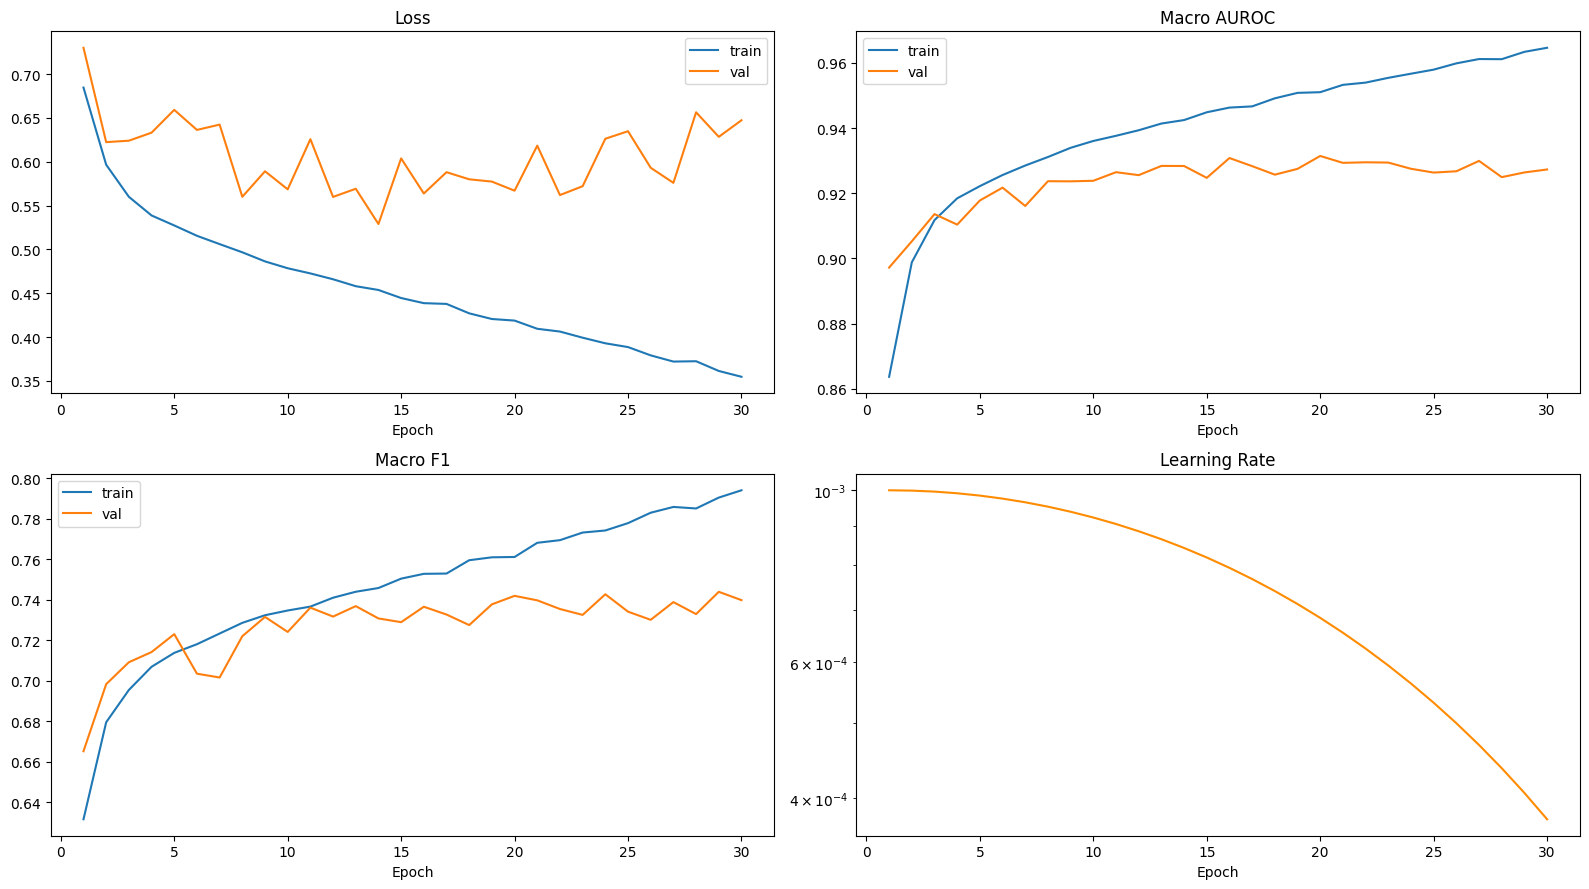

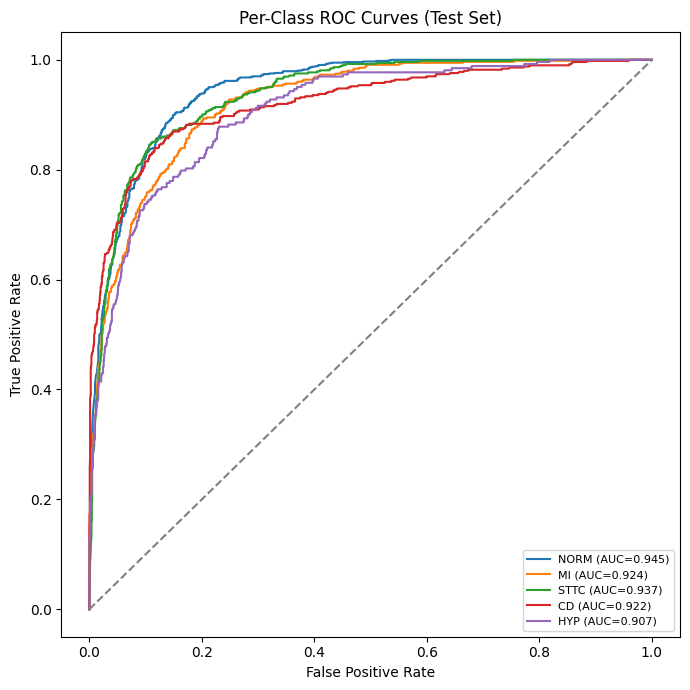

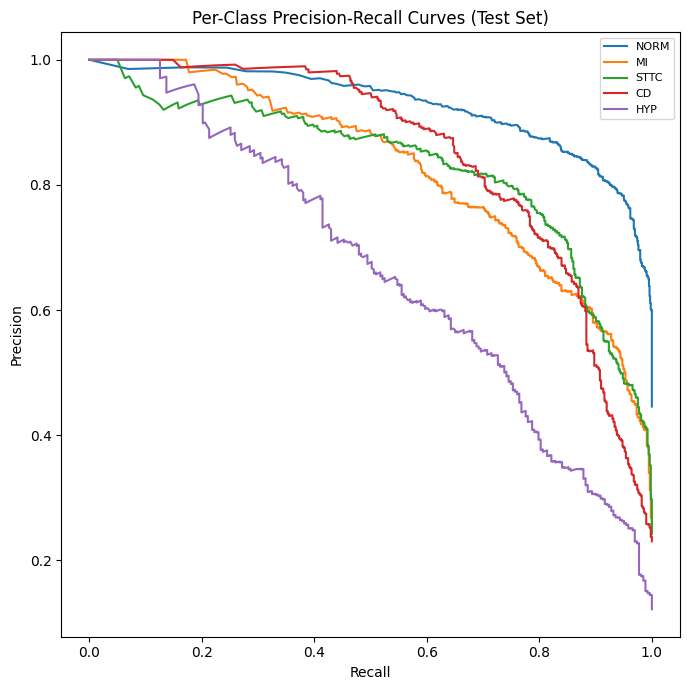

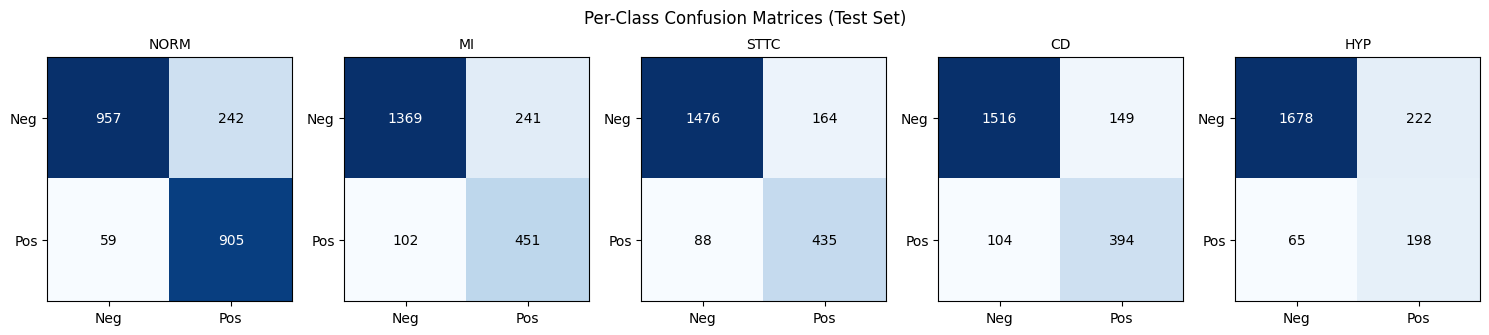

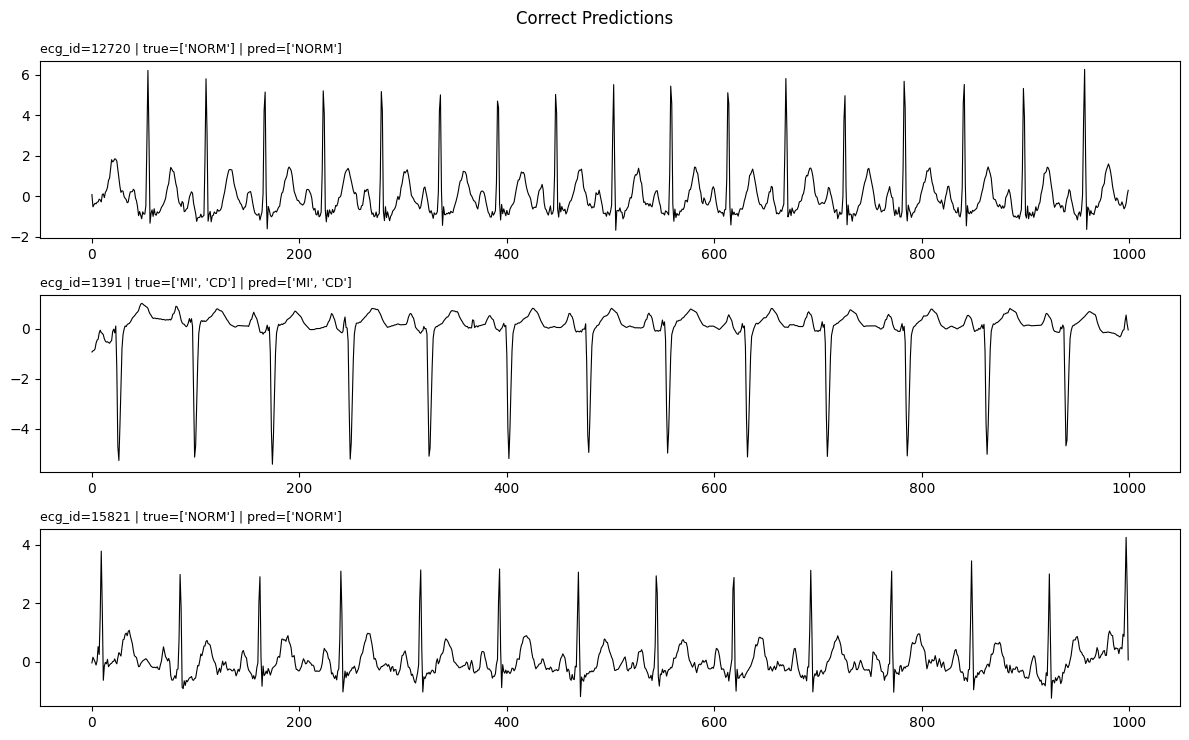

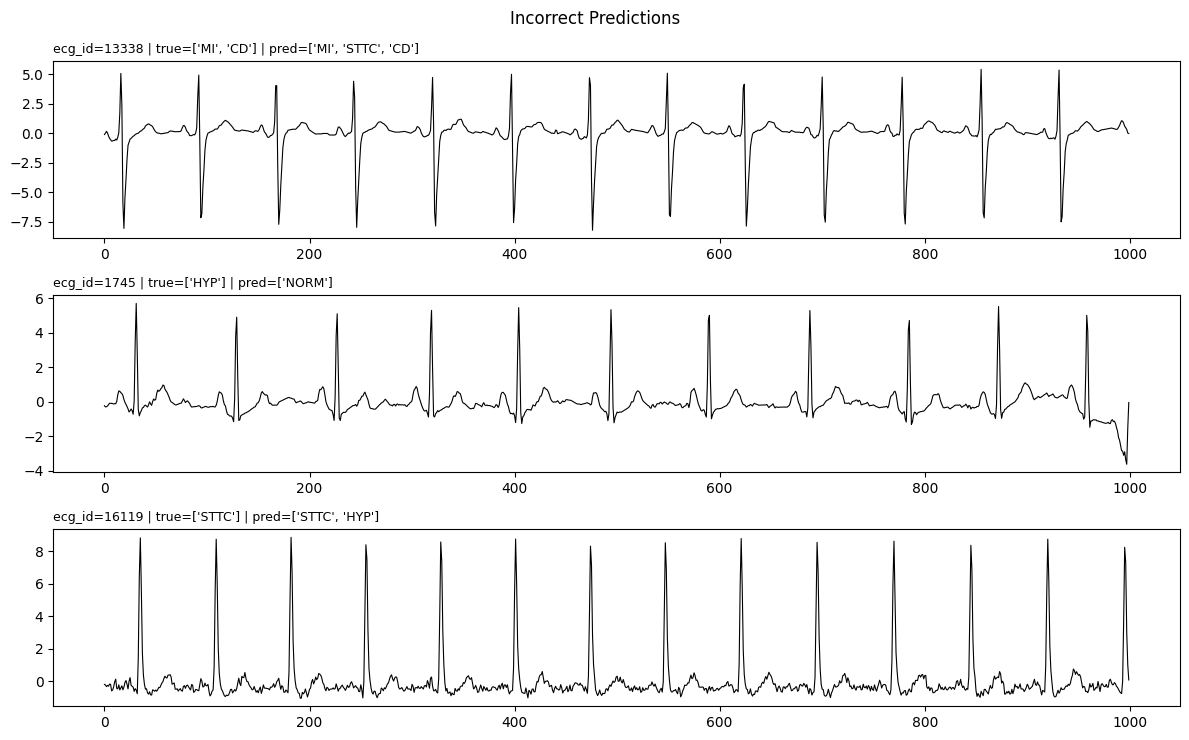

In [19]:
# Section 17 — Visualization
# ---------------------------------------------------------------------------

class Visualizer:
    '''Publication-style plotting utilities for training curves and evaluation results.

    Parameters
    ----------
    figures_dir : str
        Directory to save generated figures.
    class_names : Sequence[str]
    '''

    def __init__(self, figures_dir: str = CONFIG.FIGURES_DIR, class_names: Sequence[str] = CONFIG.SUPERCLASSES):
        self.figures_dir = figures_dir
        self.class_names = list(class_names)

    def plot_training_curves(self, history: pd.DataFrame) -> None:
        '''Plot train/val loss, AUROC, F1, and learning-rate curves across epochs.'''
        fig, axes = plt.subplots(2, 2, figsize=CONFIG.FIGSIZE_GRID)
        epochs = np.arange(1, len(history) + 1)

        axes[0, 0].plot(epochs, history.get("train/loss", pd.Series(dtype=float)), label="train")
        axes[0, 0].plot(epochs, history.get("val/loss", pd.Series(dtype=float)), label="val")
        axes[0, 0].set_title("Loss"); axes[0, 0].legend(); axes[0, 0].set_xlabel("Epoch")

        axes[0, 1].plot(epochs, history.get("train/auroc_macro", pd.Series(dtype=float)), label="train")
        axes[0, 1].plot(epochs, history.get("val/auroc_macro", pd.Series(dtype=float)), label="val")
        axes[0, 1].set_title("Macro AUROC"); axes[0, 1].legend(); axes[0, 1].set_xlabel("Epoch")

        axes[1, 0].plot(epochs, history.get("train/f1_macro", pd.Series(dtype=float)), label="train")
        axes[1, 0].plot(epochs, history.get("val/f1_macro", pd.Series(dtype=float)), label="val")
        axes[1, 0].set_title("Macro F1"); axes[1, 0].legend(); axes[1, 0].set_xlabel("Epoch")

        axes[1, 1].plot(epochs, history.get("lr", pd.Series(dtype=float)), color="darkorange")
        axes[1, 1].set_title("Learning Rate"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].set_yscale("log")

        plt.tight_layout()
        plt.savefig(os.path.join(self.figures_dir, "17_training_curves.png"))
        plt.show()

    def plot_roc_curves(self, y_true: np.ndarray, y_prob: np.ndarray) -> None:
        '''Per-class ROC curves in one figure.'''
        fig, ax = plt.subplots(figsize=CONFIG.FIGSIZE_SQUARE)
        for i, cls in enumerate(self.class_names):
            if len(np.unique(y_true[:, i])) < 2:
                continue
            fpr, tpr, _ = roc_curve(y_true[:, i], y_prob[:, i])
            ax.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
        ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
        ax.set_title("Per-Class ROC Curves (Test Set)"); ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(self.figures_dir, "17_roc_curves.png"))
        plt.show()

    def plot_pr_curves(self, y_true: np.ndarray, y_prob: np.ndarray) -> None:
        '''Per-class Precision-Recall curves (more informative than ROC under class imbalance).'''
        fig, ax = plt.subplots(figsize=CONFIG.FIGSIZE_SQUARE)
        for i, cls in enumerate(self.class_names):
            if len(np.unique(y_true[:, i])) < 2:
                continue
            precision, recall, _ = precision_recall_curve(y_true[:, i], y_prob[:, i])
            ax.plot(recall, precision, label=cls)
        ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
        ax.set_title("Per-Class Precision-Recall Curves (Test Set)"); ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(self.figures_dir, "17_pr_curves.png"))
        plt.show()

    def plot_confusion_matrices(self, y_true: np.ndarray, y_pred: np.ndarray) -> None:
        '''Grid of per-class binary confusion matrices (present vs. absent).'''
        n = len(self.class_names)
        fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.2))
        for i, (ax, cls) in enumerate(zip(axes, self.class_names)):
            cm = confusion_matrix(y_true[:, i], y_pred[:, i], labels=[0, 1])
            ax.imshow(cm, cmap="Blues")
            for (r, c), val in np.ndenumerate(cm):
                ax.text(c, r, str(val), ha="center", va="center",
                        color="white" if val > cm.max() / 2 else "black")
            ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
            ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
            ax.set_title(cls, fontsize=10)
        plt.suptitle("Per-Class Confusion Matrices (Test Set)")
        plt.tight_layout()
        plt.savefig(os.path.join(self.figures_dir, "17_confusion_matrices.png"))
        plt.show()

    def plot_prediction_examples(self, dataset: Dataset, y_true: np.ndarray, y_prob: np.ndarray,
                                  ecg_ids: List[int], n_examples: int = 3) -> None:
        '''Plot a few correctly- and incorrectly-classified ECG examples (Lead II) with true/predicted labels.'''
        y_pred = (y_prob >= 0.5).astype(int)
        correct_mask = (y_pred == y_true).all(axis=1)
        id_to_pos = {eid: i for i, eid in enumerate(dataset.ecg_ids)}

        for title, mask in [("Correct Predictions", correct_mask), ("Incorrect Predictions", ~correct_mask)]:
            idx = np.where(mask)[0]
            if len(idx) == 0:
                continue
            chosen = np.random.default_rng(CONFIG.RANDOM_SEED).choice(idx, size=min(n_examples, len(idx)), replace=False)
            fig, axes = plt.subplots(len(chosen), 1, figsize=(12, 2.5 * len(chosen)), squeeze=False)
            for ax, i in zip(axes[:, 0], chosen):
                ecg_id = ecg_ids[i]
                signal, _, _ = dataset[id_to_pos[ecg_id]]
                true_labels = [self.class_names[j] for j, v in enumerate(y_true[i]) if v > 0.5] or ["(none)"]
                pred_labels = [self.class_names[j] for j, v in enumerate(y_prob[i]) if v >= 0.5] or ["(none)"]
                ax.plot(signal[1].numpy(), linewidth=0.8, color="black")
                ax.set_title(f"ecg_id={ecg_id} | true={true_labels} | pred={pred_labels}", fontsize=9, loc="left")
            plt.suptitle(title)
            plt.tight_layout()
            safe_title = title.lower().replace(" ", "_")
            plt.savefig(os.path.join(self.figures_dir, f"17_examples_{safe_title}.png"))
            plt.show()


visualizer = Visualizer()
visualizer.plot_training_curves(training_history)
visualizer.plot_roc_curves(y_true_test, y_prob_test)
visualizer.plot_pr_curves(y_true_test, y_prob_test)
visualizer.plot_confusion_matrices(y_true_test, y_pred_test)
visualizer.plot_prediction_examples(test_dataset, y_true_test, y_prob_test, test_ecg_ids)


## Section 18 — Model Explainability

`GradCAM1D` implements Grad-CAM (Selvaraju et al., 2017) adapted to 1D convolutions: gradients of a
target class's logit with respect to the last residual stage's feature maps are global-average-pooled
into per-channel importance weights, which reweight and sum the feature maps into a 1D saliency curve
over time — highlighting which part of the 10 s window drove a given prediction (e.g., the ST segment
for an MI prediction). We also visualize raw intermediate feature maps directly for a qualitative look
at what each residual stage has learned to respond to.


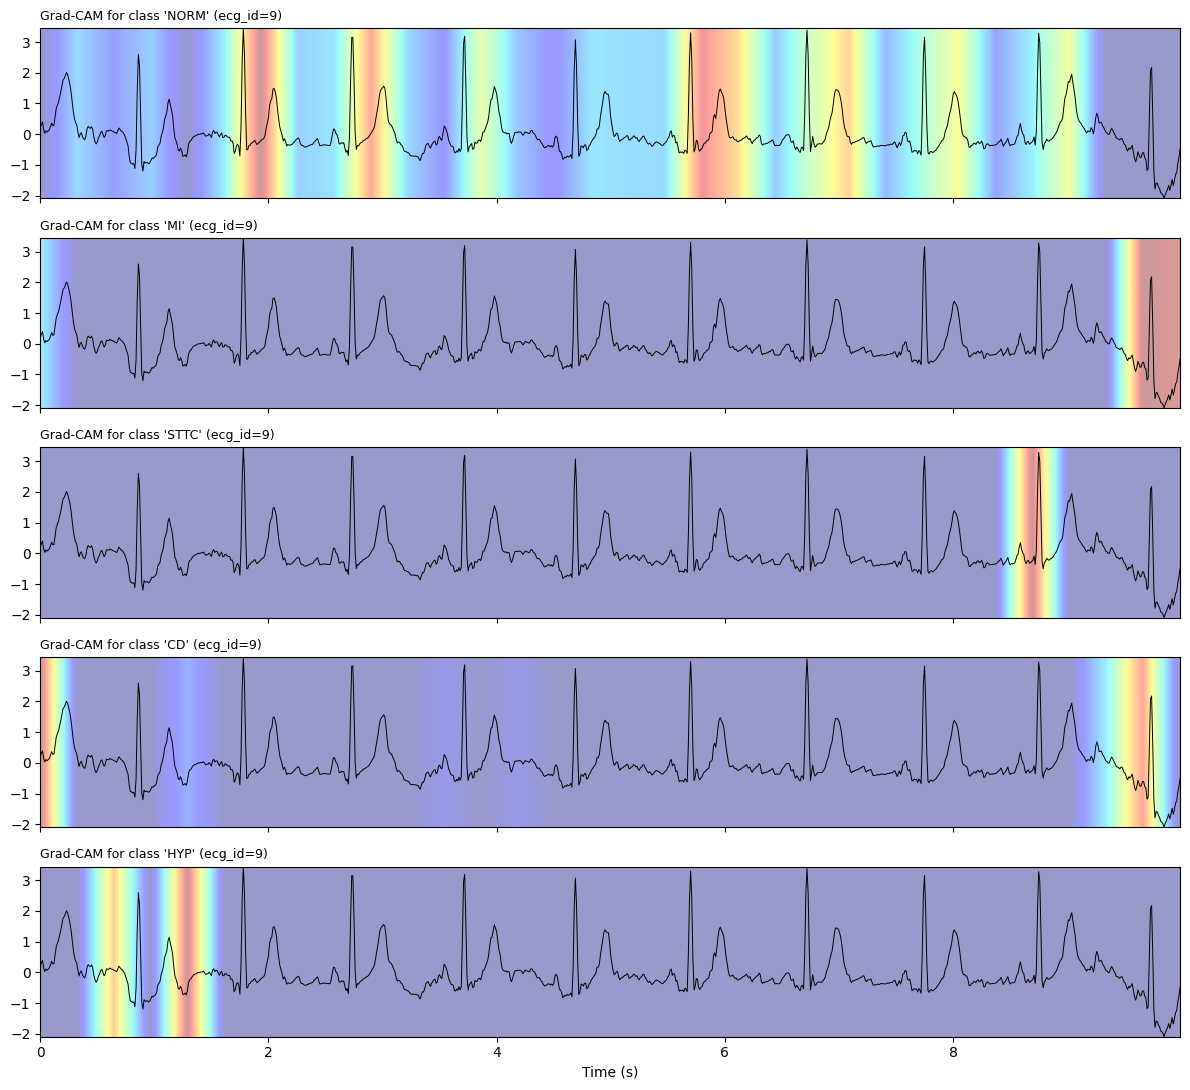

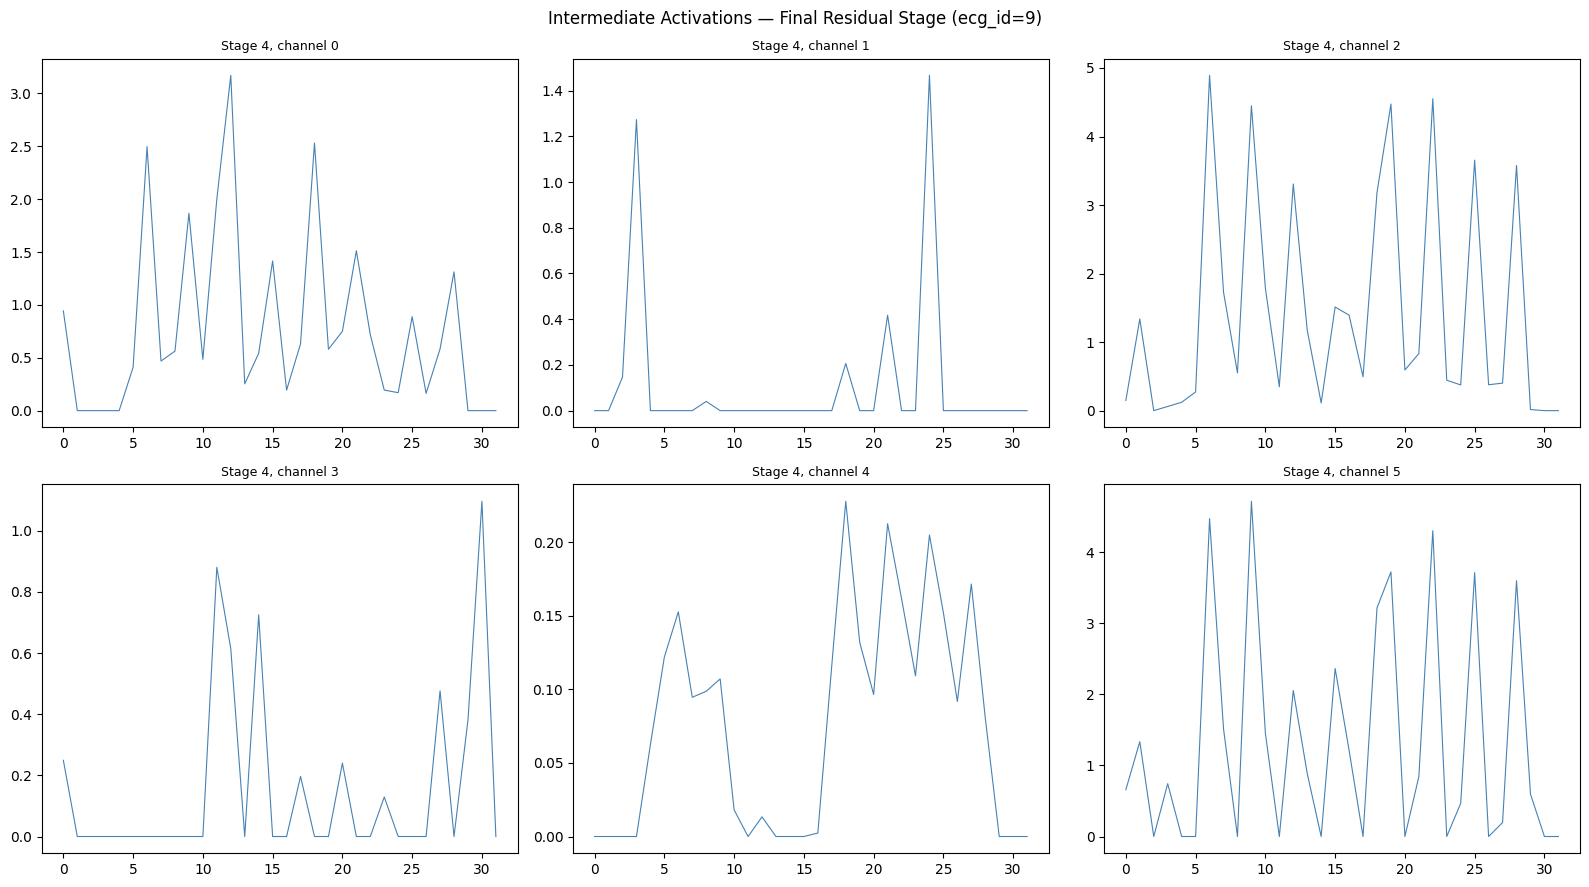

In [20]:
# Section 18 — Model Explainability
# ---------------------------------------------------------------------------

class GradCAM1D:
    '''Grad-CAM for 1D CNNs: produces a per-timestep saliency curve for a target class.

    Parameters
    ----------
    model : nn.Module
        Must expose ``model.stages`` (the last element's output is used as the CAM target layer).
    '''

    def __init__(self, model: nn.Module):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer = model.stages[-1]
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, signal: torch.Tensor, target_class: int) -> np.ndarray:
        '''Compute the Grad-CAM saliency curve for one signal and one target class index.

        Parameters
        ----------
        signal : torch.Tensor
            Shape ``(1, n_leads, n_samples)``.
        target_class : int
            Index into ``CONFIG.SUPERCLASSES``.

        Returns
        -------
        numpy.ndarray
            1D saliency curve, resampled to the input's temporal length, normalized to ``[0, 1]``.
        '''
        self.model.eval()
        signal = signal.clone().requires_grad_(True)
        logits = self.model(signal)
        score = logits[0, target_class]
        self.model.zero_grad()
        score.backward()

        weights = self.gradients.mean(dim=-1, keepdim=True)          # global-average-pool gradients
        cam = F.relu((weights * self.activations).sum(dim=1))        # weighted sum over channels
        cam = cam.squeeze(0).cpu().numpy()
        cam = np.interp(np.linspace(0, len(cam) - 1, signal.shape[-1]), np.arange(len(cam)), cam)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


gradcam = GradCAM1D(model)
example_signal, example_label, example_id = test_dataset[0]
example_input = example_signal.unsqueeze(0).to(CONFIG.DEVICE)

fig, axes = plt.subplots(CONFIG.N_CLASSES, 1, figsize=(12, 2.2 * CONFIG.N_CLASSES), sharex=True)
t = np.arange(CONFIG.SIGNAL_LENGTH) / CONFIG.SAMPLING_RATE
for i, (ax, cls) in enumerate(zip(axes, CONFIG.SUPERCLASSES)):
    cam = gradcam.generate(example_input, target_class=i)
    ax.plot(t, example_signal[1].numpy(), color="black", linewidth=0.7, label="Lead II")
    ax.imshow(cam[np.newaxis, :], extent=[t[0], t[-1], example_signal[1].min(), example_signal[1].max()],
              aspect="auto", cmap="jet", alpha=0.4)
    ax.set_title(f"Grad-CAM for class '{cls}' (ecg_id={example_id})", fontsize=9, loc="left")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG.FIGURES_DIR, "18_gradcam.png"))
plt.show()

# Intermediate feature-map / activation visualization (Stage 4, first 6 channels).
with torch.no_grad():
    feature_maps = model.get_feature_maps(example_input)
last_stage_maps = feature_maps[-1].squeeze(0).cpu().numpy()   # (channels, reduced_time)

fig, axes = plt.subplots(2, 3, figsize=CONFIG.FIGSIZE_GRID)
for ax, ch in zip(axes.flatten(), range(min(6, last_stage_maps.shape[0]))):
    ax.plot(last_stage_maps[ch], color="steelblue", linewidth=0.8)
    ax.set_title(f"Stage 4, channel {ch}", fontsize=9)
plt.suptitle(f"Intermediate Activations — Final Residual Stage (ecg_id={example_id})")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG.FIGURES_DIR, "18_feature_maps.png"))
plt.show()


## Section 19 — Performance Analysis

Computational-cost figures every future architecture notebook will report identically, so Notebook 07
can compare accuracy **per FLOP** and **per millisecond**, not just accuracy in isolation.


In [21]:
# Section 19 — Performance Analysis
# ---------------------------------------------------------------------------

total_params, trainable_params = count_parameters(model)
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

if _HAS_THOP:
    dummy_input = torch.randn(1, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH).to(CONFIG.DEVICE)
    macs, _ = thop_profile(copy.deepcopy(model), inputs=(dummy_input,), verbose=False)
    print(f"MACs (per sample)    : {macs / 1e6:.2f} M")
    print(f"FLOPs (approx, 2xMACs): {2 * macs / 1e6:.2f} M")
else:
    print("[INFO] thop not available — MACs/FLOPs skipped.")

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        _ = model(torch.randn(CONFIG.BATCH_SIZE, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH).to(CONFIG.DEVICE))
    print(f"Peak GPU memory (1 batch, inference): {torch.cuda.max_memory_allocated() / 1e6:.1f} MB")
else:
    print("[INFO] No CUDA device — GPU memory profiling skipped.")

avg_epoch_time = training_history["epoch_time_sec"].dropna().mean() if "epoch_time_sec" in training_history else float("nan")
print(f"Average epoch time   : {avg_epoch_time:.2f} s" if not np.isnan(avg_epoch_time) else "Average epoch time unavailable.")

# Per-ECG inference time and throughput (single-sample, single-batch timing).
model.eval()
n_timing_runs = 50
single_input = torch.randn(1, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH).to(CONFIG.DEVICE)
if torch.cuda.is_available():
    torch.cuda.synchronize()
start = time.perf_counter()
with torch.no_grad():
    for _ in range(n_timing_runs):
        _ = model(single_input)
if torch.cuda.is_available():
    torch.cuda.synchronize()
per_ecg_ms = (time.perf_counter() - start) / n_timing_runs * 1000
print(f"Inference time per ECG: {per_ecg_ms:.2f} ms  (~{1000 / per_ecg_ms:.1f} ECGs/sec, batch size 1)")

perf_summary = pd.DataFrame([{
    "total_params": total_params, "trainable_params": trainable_params,
    "macs_million": macs / 1e6 if _HAS_THOP else np.nan,
    "avg_epoch_time_sec": avg_epoch_time,
    "inference_time_ms_per_ecg": per_ecg_ms,
    "throughput_ecg_per_sec": 1000 / per_ecg_ms,
}])
display(perf_summary)


Total parameters     : 3,851,397
Trainable parameters : 3,851,397
MACs (per sample)    : 176.57 M
FLOPs (approx, 2xMACs): 353.14 M
Peak GPU memory (1 batch, inference): 175.2 MB
Average epoch time   : 70.21 s
Inference time per ECG: 2.56 ms  (~390.7 ECGs/sec, batch size 1)


,total_params,trainable_params,macs_million,avg_epoch_time_sec,inference_time_ms_per_ecg,throughput_ecg_per_sec
0,3851397,3851397,176.568832,70.207846,2.559445,390.709766


## Section 20 — Error Analysis

We break down test-set errors by class (false positives/negatives, rare-class performance) and inspect
which class pairs the model confuses most often (co-occurring error patterns) — the same breakdown
every future notebook will produce, so weaknesses can be tracked architecture-to-architecture in
Notebook 07.


Per-class error breakdown (sorted by rarity):


,class,n_positive,true_positive,false_positive,false_negative,true_negative,recall,precision
4,HYP,263,198,222,65,1678,0.752852,0.471429
3,CD,498,394,149,104,1516,0.791165,0.725599
2,STTC,523,435,164,88,1476,0.831740,0.726210
1,MI,553,451,241,102,1369,0.815552,0.651734
0,NORM,964,905,242,59,957,0.938797,0.789015



Rarest class in the test set: 'HYP' — recall=0.753, precision=0.471. Rare-class recall is the metric most worth tracking as later notebooks (Mamba/SSL) are introduced.

Co-occurring error counts (off-diagonal = classes frequently mis-predicted together):


,NORM,MI,STTC,CD,HYP
NORM,301,100,61,54,53
MI,100,343,56,38,66
STTC,61,56,252,31,57
CD,54,38,31,253,35
HYP,53,66,57,35,287


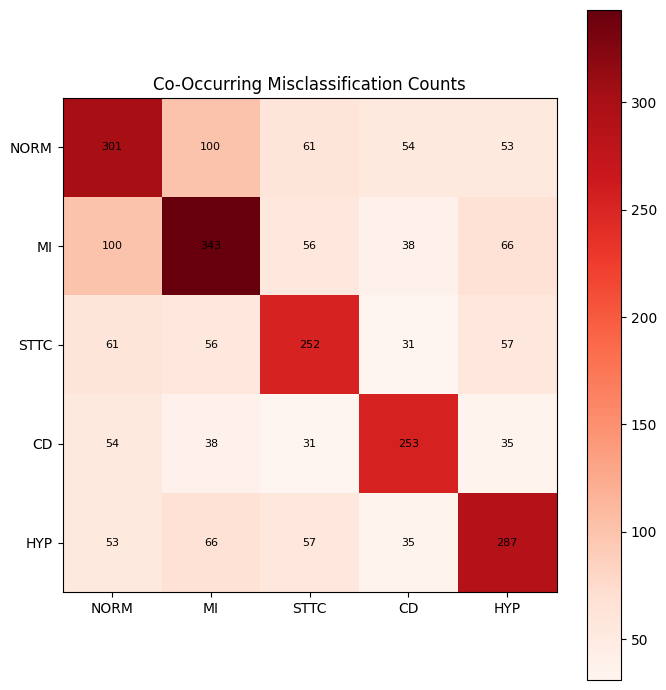


Example misclassified ecg_ids for manual review: [38, 65, 116, 128, 132]


In [22]:
# Section 20 — Error Analysis
# ---------------------------------------------------------------------------

error_rows = []
for i, cls in enumerate(CONFIG.SUPERCLASSES):
    tn, fp, fn, tp = confusion_matrix(y_true_test[:, i], y_pred_test[:, i], labels=[0, 1]).ravel()
    error_rows.append({
        "class": cls, "n_positive": int(tp + fn), "true_positive": int(tp), "false_positive": int(fp),
        "false_negative": int(fn), "true_negative": int(tn),
        "recall": tp / (tp + fn) if (tp + fn) else np.nan,
        "precision": tp / (tp + fp) if (tp + fp) else np.nan,
    })
error_table = pd.DataFrame(error_rows).sort_values("n_positive")
print("Per-class error breakdown (sorted by rarity):")
display(error_table)

rarest_class = error_table.iloc[0]["class"]
print(f"\nRarest class in the test set: '{rarest_class}' — "
      f"recall={error_table.iloc[0]['recall']:.3f}, precision={error_table.iloc[0]['precision']:.3f}. "
      "Rare-class recall is the metric most worth tracking as later notebooks (Mamba/SSL) are introduced.")

# Confusing class pairs: how often are two classes BOTH misclassified on the same record?
error_matrix = (y_pred_test != y_true_test).astype(int)   # (n_samples, n_classes)
co_error = error_matrix.T @ error_matrix
co_error_df = pd.DataFrame(co_error, index=CONFIG.SUPERCLASSES, columns=CONFIG.SUPERCLASSES)
print("\nCo-occurring error counts (off-diagonal = classes frequently mis-predicted together):")
display(co_error_df)

fig, ax = plt.subplots(figsize=CONFIG.FIGSIZE_SQUARE)
im = ax.imshow(co_error_df.values, cmap="Reds")
ax.set_xticks(range(len(CONFIG.SUPERCLASSES))); ax.set_yticks(range(len(CONFIG.SUPERCLASSES)))
ax.set_xticklabels(CONFIG.SUPERCLASSES); ax.set_yticklabels(CONFIG.SUPERCLASSES)
for (r, c), val in np.ndenumerate(co_error_df.values):
    ax.text(c, r, str(val), ha="center", va="center", fontsize=8)
ax.set_title("Co-Occurring Misclassification Counts")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG.FIGURES_DIR, "20_confusing_classes.png"))
plt.show()

# A handful of concrete misclassified examples for qualitative review.
misclassified_mask = (y_pred_test != y_true_test).any(axis=1)
misclassified_ids = np.array(test_ecg_ids)[misclassified_mask][:5]
print(f"\nExample misclassified ecg_ids for manual review: {misclassified_ids.tolist()}")


## Section 21 — Save Outputs

In [23]:
# Section 21 — Save Outputs
# ---------------------------------------------------------------------------

# best_resnet1d.pth / last_checkpoint.pth already written continuously by CheckpointManager during training.
best_path = os.path.join(CONFIG.CHECKPOINT_DIR, f"best_{CONFIG.MODEL_NAME}.pth")
last_path = os.path.join(CONFIG.CHECKPOINT_DIR, "last_checkpoint.pth")

training_history_path = os.path.join(CONFIG.TABLES_DIR, "training_history.csv")
training_history.to_csv(training_history_path, index=False)

eval_rows = {k: v for k, v in test_metrics.items() if k != "per_class_auroc"}
eval_rows.update({f"auroc_{cls}": v for cls, v in test_metrics["per_class_auroc"].items()})
evaluation_metrics_path = os.path.join(CONFIG.TABLES_DIR, "evaluation_metrics.csv")
pd.DataFrame([eval_rows]).to_csv(evaluation_metrics_path, index=False)

predictions_path = os.path.join(CONFIG.TABLES_DIR, "predictions.csv")
predictions_df.to_csv(predictions_path, index=False)

classification_report_lines = ["ResNet1D — PTB-XL Multi-Label Classification Report (Test Set / Fold 10)",
                                "=" * 70]
for _, row in error_table.iterrows():
    classification_report_lines.append(
        f"{row['class']:>6}: precision={row['precision']:.4f}  recall={row['recall']:.4f}  "
        f"n_positive={row['n_positive']}"
    )
classification_report_lines.append("-" * 70)
classification_report_lines.append(
    f"Overall: AUROC(macro)={test_metrics['auroc_macro']:.4f}  AUROC(micro)={test_metrics['auroc_micro']:.4f}  "
    f"F1(macro)={test_metrics['f1_macro']:.4f}  F1(micro)={test_metrics['f1_micro']:.4f}  "
    f"Subset accuracy={test_metrics['subset_accuracy']:.4f}"
)
classification_report_path = os.path.join(CONFIG.TABLES_DIR, "classification_report.txt")
with open(classification_report_path, "w") as f:
    f.write("\n".join(classification_report_lines))

for label, path in [
    ("best_resnet1d.pth", best_path), ("last_checkpoint.pth", last_path),
    ("training_history.csv", training_history_path), ("evaluation_metrics.csv", evaluation_metrics_path),
    ("predictions.csv", predictions_path), ("classification_report.txt", classification_report_path),
]:
    if os.path.exists(path):
        print(f"Saved {label:<26} -> {path}  ({os.path.getsize(path) / 1024:.1f} KB)")
    else:
        print(f"[WARN] Expected output missing: {path}")

logger.close()


Saved best_resnet1d.pth          -> ./resnet1d_outputs/checkpoints/best_resnet1d.pth  (45266.0 KB)
Saved last_checkpoint.pth        -> ./resnet1d_outputs/checkpoints/last_checkpoint.pth  (45266.7 KB)
Saved training_history.csv       -> ./resnet1d_outputs/tables/training_history.csv  (12.7 KB)
Saved evaluation_metrics.csv     -> ./resnet1d_outputs/tables/evaluation_metrics.csv  (0.4 KB)
Saved predictions.csv            -> ./resnet1d_outputs/tables/predictions.csv  (155.4 KB)
Saved classification_report.txt  -> ./resnet1d_outputs/tables/classification_report.txt  (0.6 KB)


## Section 22 — Research Discussion

### Strengths of ResNet1D
- Strong, well-understood baseline; residual connections make it trainable at meaningful depth without
  the plain-CNN degradation problem.
- Input-length agnostic (global average pooling), so the exact same architecture serves 100 Hz or
  500 Hz recordings unmodified.
- Fast to train and cheap at inference relative to recurrent or attention-based alternatives, which
  matters for the T4's 16GB budget.

### Weaknesses
- Fixed, local receptive field growth (convolutional) makes capturing very long-range dependencies
  (e.g., inter-beat rhythm context beyond a few seconds) less natural than sequence models.
- Translation-equivariant convolutions do not explicitly model the specific inter-lead physiological
  structure (Einthoven/Goldberger relations) — the network must learn this implicitly from data.
- Purely supervised — cannot exploit unlabeled ECG data, unlike the SSL objective planned for
  Notebook 06.

### Computational cost
Section 19's parameter count, MACs, and per-ECG inference time establish the **baseline cost budget**
against which InceptionTime's multi-scale branches, Mamba's sequence-state-space cost, and the
SSL-pretraining overhead in later notebooks will be measured.

### Generalization ability
Test-set (fold 10, never seen during training or model selection) macro AUROC — reported in Section
16/19 — is the headline generalization number; Section 20's rare-class recall is the sharper lens,
since a model can post a strong macro AUROC while still underperforming badly on the rarest class.

### Potential improvements
- Class-balanced sampling or focal loss tuning (already implemented, `CONFIG.USE_FOCAL_LOSS`) targeted
  specifically at HYP/rare-CD-subtype recall.
- Multi-scale convolutional stems (motivating Notebook 04's InceptionTime) to capture morphology at
  several time scales simultaneously without manually tuning kernel size.
- Test-time augmentation (multiple crops/lead-subsets averaged) for a cheap, training-free accuracy gain.

### How Mamba may improve over ResNet1D
Mamba's selective state-space mechanism scales *linearly* with sequence length (vs. a Transformer's
quadratic attention cost) while maintaining an effectively unbounded receptive field — in principle
combining ResNet1D's efficiency with a much longer effective context window, which could help exactly
the long-range-rhythm weaknesses noted above. Notebook 05 will measure this directly against the cost
and generalization numbers established here.


## Section 23 — Notebook Summary

### Architecture
A ResNet18-style 1D CNN (`ResNet1D`): wide-kernel stem, 4 residual stages (64→128→256→512 channels,
2 blocks each), global average pooling, dropout, and a linear multi-label head — see Section 8's
parameter count and architecture diagram for exact specifications.

### Training
`BCEWithLogitsLoss` (optionally class-weighted or focal), `AdamW`, cosine-annealed learning rate, mixed
precision (`torch.amp`), gradient clipping, early stopping on validation macro AUROC, automatic
best/last checkpointing, and TensorBoard logging — all via the reusable `Trainer`/`Logger`/
`CheckpointManager` framework in Section 14.

### Evaluation
Full multi-label metric suite (subset accuracy, macro/micro precision/recall/F1/AUROC, per-class AUROC)
via `MetricsCalculator`; ROC/PR curves, confusion matrices, Grad-CAM explainability, and detailed
per-class + confusing-class-pair error analysis — see Sections 16, 17, 18, and 20.

### Performance
Parameter count, MACs/FLOPs, GPU memory, average epoch time, and per-ECG inference latency (Section 19)
establish the computational baseline every later architecture in this project will be measured against.

### Future work
The **`Trainer`, `Evaluator`, `MetricsCalculator`, `Logger`, `CheckpointManager`, and `Visualizer`**
classes defined here are architecture-agnostic and require **no changes** in Notebooks 04-06 — only a
new `model = ...` instantiation is needed. **Notebook 04 will implement InceptionTime** as the next
architecture for comparison against this ResNet1D baseline, using this exact same training/evaluation
framework and identical preprocessing (Notebook 02) and official fold splits, so every later comparison
in Notebook 07 is apples-to-apples.
